# Ensemble Learning Assignment: Forecasting Pettah Wholesale Beans Prices

**Prakasan R. (224152U)**

**Problem:** predict next week's average wholesale price of beans at Pettah market, so farmers, traders and small eateries can plan when to buy and sell.

**Data:** Central Bank of Sri Lanka, Daily Price Report, via Macro Lab (macrolab.lk), Aug 2016 to Nov 2026.


## Step 1: Load and understand the data

### Setup

Installs the boosting libraries used in Step 6 (XGBoost and CatBoost) (scikit-learn, pandas, numpy and matplotlib come with Anaconda). `%pip` installs into the same Python environment the notebook runs on. If they are already installed, this cell finishes quickly.

In [1]:
%pip install -q xgboost catboost

Note: you may need to restart the kernel to use updated packages.


## Step 1: Load, check and clean the price data

Load the Macro Lab file. `comment="#"` skips the 6 note lines at the top of the file, and `parse_dates` turns `period` into real dates so the days can be grouped into weeks later.

In [2]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(max(1, os.cpu_count() // 2))   # about the number of physical cores; stops a harmless joblib traceback on Windows

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/daily-prices-d.csv", comment="#", parse_dates=["period"])
df.shape

(2470, 263)

### Choosing the columns

The file has 262 price series; only four are kept:
- `beans_pettah`: the **target** (Pettah wholesale beans, Rs/kg).
- `beans_dambulla`: Dambulla is a large wholesale centre closer to the farms, so its price can move before Pettah's.
- `carrot_pettah`, `cabbage_pettah`: grown in the same upcountry areas, so the same weather and transport problems affect them.

The date becomes the index so pandas can group the days into weeks.

In [3]:
cols = {
    "Beans (wholesale, pettah) (Rs/kg)":   "beans_pettah",
    "Beans (wholesale, dambulla) (Rs/kg)": "beans_dambulla",
    "Carrot (wholesale, pettah) (Rs/kg)":  "carrot_pettah",
    "Cabbage (wholesale, pettah) (Rs/kg)": "cabbage_pettah",
}

data = df[["period"] + list(cols)].rename(columns=cols)
data = data.rename(columns={"period": "date"}).set_index("date").sort_index()
data.head()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
date,,,,
2016-08-01,140.0,130.0,100.0,80.0
2016-08-02,140.0,145.0,100.0,80.0
2016-08-03,120.0,155.0,100.0,70.0
2016-08-04,105.0,150.0,100.0,60.0
2016-08-05,105.0,150.0,100.0,60.0


In [4]:
print(data.isna().sum())
data.describe().round(1)

beans_pettah      79
beans_dambulla    62
carrot_pettah     80
cabbage_pettah    80
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
count,2391.0,2408.0,2390.0,2390.0
mean,272.4,243.8,212.6,136.0
std,167.8,146.6,166.0,105.7
min,30.0,30.0,35.0,15.0
25%,140.0,125.0,100.0,65.0
50%,220.0,205.0,163.0,100.0
75%,400.0,325.0,280.0,180.0
max,1200.0,1100.0,2000.0,700.0


**What this shows:**
- The mean beans price (Rs 272) is well above the median (Rs 220), so a few very high prices pull the average up: the distribution is right-skewed.
- Prices range from Rs 30 to Rs 1,200 per kg, a very volatile market.
- 79 days have no beans price. These are days with no report (holidays and closures), handled below.

### Weekly averages

Daily prices are converted to weekly averages (weeks ending Friday) because:
1. there are no reports on weekends and holidays, and weekly averages smooth over these gaps;
2. daily prices are noisy, and the weekly average shows the real direction;
3. traders and farmers plan by the week, so next week's price is a useful thing to predict.

The last row is dropped because the current week is not finished, and a partial week would give a misleading average.

In [5]:
weekly = data.resample("W-FRI").mean()
weekly = weekly.iloc[:-1]      # drop the current week, which isn't finished yet
print(weekly.shape)
print(weekly.isna().sum())

(537, 4)
beans_pettah      10
beans_dambulla     3
carrot_pettah     10
cabbage_pettah    10
dtype: int64


In [6]:
weekly[weekly["beans_pettah"].isna()].index


DatetimeIndex(['2020-04-17', '2020-04-24', '2020-10-30', '2020-11-06',
               '2020-11-13', '2020-11-20', '2020-11-27', '2020-12-04',
               '2020-12-11', '2026-04-17'],
              dtype='datetime64[ns]', name='date', freq=None)

**Where the gaps are:** the 10 weeks with no beans price fall in April 2020, late October to mid-December 2020, and mid-April 2026. They match the COVID-19 lockdowns and the Sinhala and Tamil New Year (Avurudu) holiday, when markets closed and no reports were published. The gaps are not random errors.

### Filling the gaps

A `was_missing` flag is created first, so the record of which weeks were estimated is kept. Each gap is then filled by time interpolation (a straight line between the weeks on either side). The rows are not deleted, because the lag features in Step 3 need an unbroken weekly sequence. Almost all gaps are in 2020, which is in the training period, so the final test results are not affected.

In [7]:
weekly["was_missing"] = weekly["beans_pettah"].isna().astype(int)
weekly = weekly.interpolate(method="time")
weekly.isna().sum()



beans_pettah      0
beans_dambulla    0
carrot_pettah     0
cabbage_pettah    0
was_missing       0
dtype: int64

### Data checks

Before the data is used, these checks confirm that there are no duplicate days, no zero or negative prices, that every week is exactly 7 days after the previous one (so "last week" in Step 3 really means the previous week), and that no gaps are left.

In [8]:
assert not data.index.duplicated().any(), "duplicate days"
assert (data.dropna() > 0).all().all(), "zero or negative price"
week_gaps = weekly.index.to_series().diff().dropna()
assert (week_gaps == pd.Timedelta(days=7)).all(), "weeks not 7 days apart"
assert weekly.isna().sum().sum() == 0, "missing values left"
print(f"Checks passed: {len(data)} days with no duplicate dates and no zero or negative prices; "
      f"{len(weekly)} weeks, each 7 days after the previous one, with no missing values left")

Checks passed: 2470 days with no duplicate dates and no zero or negative prices; 537 weeks, each 7 days after the previous one, with no missing values left


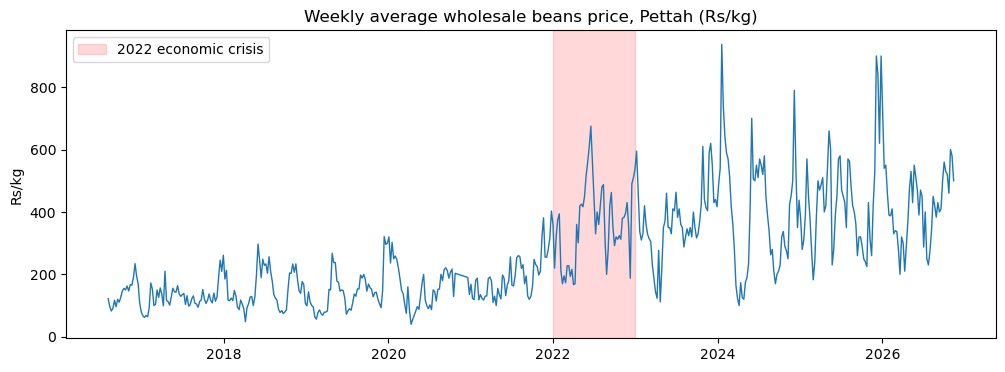

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weekly.index, weekly["beans_pettah"], linewidth=1)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"),
           alpha=0.15, color="red", label="2022 economic crisis")
ax.set_title("Weekly average wholesale beans price, Pettah (Rs/kg)")
ax.set_ylabel("Rs/kg")
ax.legend()
plt.show()

**What this shows:** prices averaged about Rs 130-160 in 2016-2019, rose in 2021 (Rs 194), then jumped in 2022 (Rs 360) and stayed high (Rs 367 in 2023, Rs 396 in 2024, Rs 433 in 2025). The highest week was 19 January 2024, at about Rs 938.

Prices more than doubled after the 2022 economic crisis and never returned to earlier levels. Tree models such as Random Forest and XGBoost cannot predict values higher than anything in their training data, so instead of the price itself, **the target will be the percentage change in price** (Step 3).

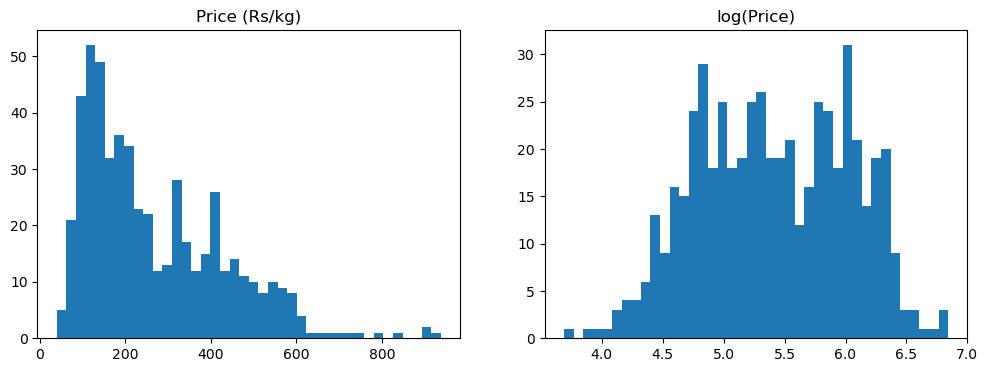

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(weekly["beans_pettah"], bins=40)
axes[0].set_title("Price (Rs/kg)")
axes[1].hist(np.log(weekly["beans_pettah"]), bins=40)
axes[1].set_title("log(Price)")
plt.show()

**What this shows:** the price distribution (left) is right-skewed, with a long tail of expensive weeks. After taking the log (right), it is much more balanced. Prices move in percentages (a Rs 50 rise matters far more at Rs 100 than at Rs 900), and the log treats a 10% rise the same at any price level. This supports using the change in log price as the target.

The cleaned weekly data is saved so later steps can start from it.

In [11]:
weekly.to_csv("dataset/weekly_clean.csv")
weekly.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0
2026-10-23,460.0,392.0,206.0,410.0,0
2026-10-30,600.0,459.0,340.0,490.0,0
2026-11-06,580.0,498.0,440.0,600.0,0
2026-11-13,500.0,409.0,540.0,620.0,0


## Step 2: Add rainfall from the growing areas

Heavy rain and floods in the upcountry growing areas damage crops and block transport, so less beans reach Pettah and the price rises. This step adds weekly rainfall for the two main beans-growing districts, **Nuwara Eliya** and **Badulla**, to test that idea and to use rainfall as a feature.

In [12]:
weekly = pd.read_csv("dataset/weekly_clean.csv", index_col="date", parse_dates=True)
print(weekly.shape)
weekly.head(3)

(537, 5)


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2016-08-05,122.0,146.0,100.0,70.00,0
2016-08-12,97.0,147.0,82.0,65.00,0
2016-08-19,82.5,125.0,85.0,71.25,0


### Downloading daily rainfall

Rainfall comes from **Open-Meteo**'s historical weather API (free, no sign-up), which provides daily rainfall in mm derived from ERA5, a global weather dataset from the EU's Copernicus programme. These are model estimates for each location, not rain-gauge readings.
- The download starts in July 2016, a month before the price data, so the first weeks of prices can still have rainfall from earlier weeks.
- It ends on 13 November 2026, the last full week of price data.
- The daily data is saved to `rain_daily.csv`, so the project works offline and can be rerun without downloading again.

In [13]:
import requests

def get_rain(lat, lon, name):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2016-07-01",
        "end_date": "2026-11-13",
        "daily": "precipitation_sum",
        "timezone": "Asia/Colombo",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.Series(d["precipitation_sum"], index=pd.to_datetime(d["time"]), name=name)

rain = pd.concat([
    get_rain(6.9497, 80.7891, "rain_nuwaraeliya"),
    get_rain(6.9934, 81.0550, "rain_badulla"),
], axis=1)
rain.index.name = "date"

rain.to_csv("dataset/rain_daily.csv")
print(rain.shape)
rain.describe().round(1)

(3788, 2)


,rain_nuwaraeliya,rain_badulla
count,3788.0,3788.0
mean,5.3,6.4
std,9.4,12.4
min,0.0,0.0
25%,0.6,0.3
50%,2.3,2.1
75%,5.9,8.1
max,193.8,265.0


In [14]:
print(rain.isna().sum())
rain.tail()

rain_nuwaraeliya    0
rain_badulla        0
dtype: int64


,rain_nuwaraeliya,rain_badulla
date,,
2026-11-09,8.9,25.7
2026-11-10,21.3,13.4
2026-11-11,15.4,28.7
2026-11-12,15.4,35.6
2026-11-13,2.2,0.6


**Result:** there are no missing days for either location. The next cell (`fillna(0)`) is kept only as a safety step in case a rerun returns missing recent days; it changes nothing here.

In [15]:
rain = rain.fillna(0)

### Weekly rainfall totals

Daily rain is summed (not averaged) per week, because the total amount that fell is what affects crops and roads. The weeks end on Friday (`W-FRI`), exactly matching the price weeks.

In [16]:
rain_weekly = rain.resample("W-FRI").sum()
rain_weekly.head()

,rain_nuwaraeliya,rain_badulla
date,,
2016-07-01,4.1,0.3
2016-07-08,10.1,0.5
2016-07-15,65.3,20.3
2016-07-22,21.9,8.9
2016-07-29,86.0,76.5


In [17]:
data2 = weekly.join(rain_weekly, how="left")
print(data2.shape)
print(data2.isna().sum())
data2.head()

(537, 7)
beans_pettah        0
beans_dambulla      0
carrot_pettah       0
cabbage_pettah      0
was_missing         0
rain_nuwaraeliya    0
rain_badulla        0
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing,rain_nuwaraeliya,rain_badulla
date,,,,,,,
2016-08-05,122.0,146.0,100.0,70.00,0,18.8,15.6
2016-08-12,97.0,147.0,82.0,65.00,0,17.7,0.9
2016-08-19,82.5,125.0,85.0,71.25,0,30.5,0.4
2016-08-26,91.0,111.0,80.0,65.00,0,47.9,13.1
2016-09-02,117.0,123.0,72.0,61.00,0,31.7,5.8


**Result:** rainfall joined to all 537 price weeks with no missing values (7 columns: 4 prices, `was_missing` and 2 rainfall columns). `how="left"` keeps every price week.

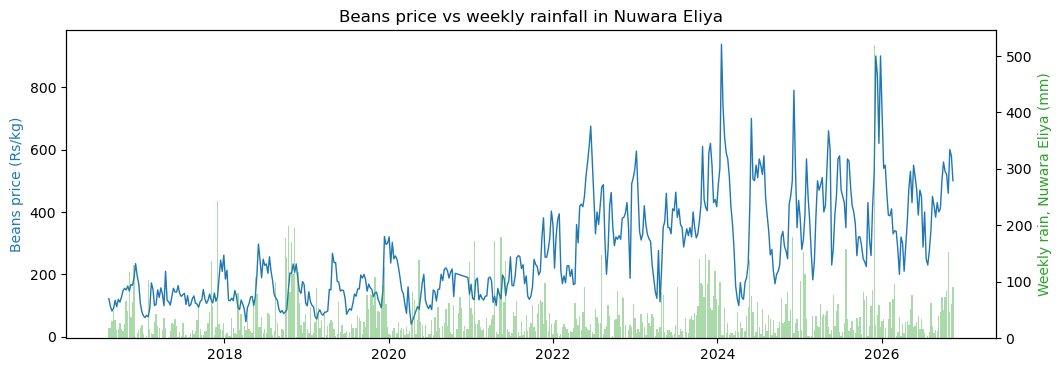

In [18]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(data2.index, data2["beans_pettah"], color="tab:blue", linewidth=1)
ax1.set_ylabel("Beans price (Rs/kg)", color="tab:blue")

ax2 = ax1.twinx()
ax2.bar(data2.index, data2["rain_nuwaraeliya"], width=6, color="tab:green", alpha=0.4)
ax2.set_ylabel("Weekly rain, Nuwara Eliya (mm)", color="tab:green")

ax1.set_title("Beans price vs weekly rainfall in Nuwara Eliya")
plt.show()

**What the chart shows:** rain is heaviest from October to December and in May (the two monsoons). Some of the biggest price jumps come right after very wet weeks, for example December 2019 (+117% after a 94 mm week in Nuwara Eliya) and late October 2025 (+91% after 75 mm). But several of the largest jumps fall in **April**, around Avurudu, after ordinary rainfall (2017, 2018, 2022, 2023). That suggests festival demand and holiday supply gaps also drive prices, not rain alone, so a festival feature is needed too.

### Does past rain relate to price changes?

The weekly % change in price is compared with rainfall from 0 to 4 weeks earlier.

In [19]:
data2["beans_change"] = np.log(data2["beans_pettah"]).diff()

for lag in range(0, 5):
    c1 = data2["beans_change"].corr(data2["rain_nuwaraeliya"].shift(lag))
    c2 = data2["beans_change"].corr(data2["rain_badulla"].shift(lag))
    print(f"rain {lag} week(s) earlier:  Nuwara Eliya {c1:.3f}   Badulla {c2:.3f}")

rain 0 week(s) earlier:  Nuwara Eliya 0.087   Badulla 0.050
rain 1 week(s) earlier:  Nuwara Eliya 0.324   Badulla 0.262
rain 2 week(s) earlier:  Nuwara Eliya 0.091   Badulla 0.068
rain 3 week(s) earlier:  Nuwara Eliya -0.139   Badulla -0.160
rain 4 week(s) earlier:  Nuwara Eliya -0.032   Badulla -0.046


**What the correlations show:** Rain one week earlier has the strongest link to price changes (r = 0.32 for Nuwara Eliya, 0.26 for Badulla): heavy rain in the growing areas is followed by a price rise in Colombo about a week later. After three weeks the relationship turns negative (r ≈ −0.15), suggesting prices fall back once supply recovers. Nuwara Eliya is more strongly related than Badulla at every lag. Based on this, I will use rainfall lagged by 1–3 weeks as features in Step 3.

The temporary `beans_change` column is dropped (Step 3 builds the target properly), and the combined weekly data is saved.

In [20]:
data2 = data2.drop(columns="beans_change")
data2.to_csv("dataset/weekly_with_rain.csv")
data2.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing,rain_nuwaraeliya,rain_badulla
date,,,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0,84.6,127.0
2026-10-23,460.0,392.0,206.0,410.0,0,153.3,98.7
2026-10-30,600.0,459.0,340.0,490.0,0,45.9,42.8
2026-11-06,580.0,498.0,440.0,600.0,0,60.7,74.6
2026-11-13,500.0,409.0,540.0,620.0,0,90.6,136.9


## Step 3: Build the target and features

**Rule for this step:** every feature must be something already known at the end of the current week. Only the target is allowed to look at next week; anything else that does is data leakage.

In [21]:
df = pd.read_csv("dataset/weekly_with_rain.csv", index_col="date", parse_dates=True)
logp = np.log(df["beans_pettah"])
feat = pd.DataFrame(index=df.index)
df.shape

(537, 7)

### Target: next week's % change in price

`shift(-1)` brings next week's log price into this week's row, so the target is log(next price) − log(this price), roughly next week's % change. I predict the change rather than the price because prices more than doubled after 2022, and tree models cannot predict values higher than anything in their training data. A % change looks the same before and after 2022.

In [22]:
feat["target"] = logp.shift(-1) - logp

### Features from beans' own recent price moves

- `chg_1` to `chg_4`: this week's and the previous three weeks' changes (recent momentum). `shift(k)` only looks back.
- `gap_ma4`: how far the price is above or below its 4-week average. Stretched prices tend to fall back (mean reversion).
- `vol_4`: how jumpy prices have been over the last 4 weeks.

In [23]:
feat["chg_1"] = logp.diff()                      # this week's change
feat["chg_2"] = feat["chg_1"].shift(1)           # last week's change
feat["chg_3"] = feat["chg_1"].shift(2)           # 2 weeks ago
feat["chg_4"] = feat["chg_1"].shift(3)           # 3 weeks ago
feat["gap_ma4"] = logp - logp.rolling(4).mean()  # distance from 4-week average
feat["vol_4"] = feat["chg_1"].rolling(4).std()   # recent volatility

### Features from other markets and vegetables

- `dambulla_gap`: Dambulla vs Pettah price. Traders move stock until the two markets meet again, so the gap hints at where Pettah is heading.
- `dambulla_chg`: Dambulla is closer to the farms, so its price often moves first.
- `carrot_chg`, `cabbage_chg`: grown in the same upcountry areas and carried on the same trucks, so they react to the same weather and transport problems.

Changes (not raw prices) keep everything on the same % scale before and after 2022.

In [24]:
feat["dambulla_gap"] = np.log(df["beans_dambulla"]) - logp
feat["dambulla_chg"] = np.log(df["beans_dambulla"]).diff()
feat["carrot_chg"]   = np.log(df["carrot_pettah"]).diff()
feat["cabbage_chg"]  = np.log(df["cabbage_pettah"]).diff()

### Rainfall features

Step 2 showed rain affects price 1-3 weeks later. Because the target is next week's change:
- `rain_*_0` (this week's rain) is rain 1 week before the target week, the strongest link (r = 0.32)
- `rain_*_1` (last week's rain) is 2 weeks before
- `rain_*_2` (rain 2 weeks ago) is 3 weeks before, where the link turned negative

So these lags come directly from the Step 2 analysis. `ne` = Nuwara Eliya, `bd` = Badulla.

In [25]:
for name, col in [("ne", "rain_nuwaraeliya"), ("bd", "rain_badulla")]:
    feat[f"rain_{name}_0"] = df[col]            # rain this week
    feat[f"rain_{name}_1"] = df[col].shift(1)   # rain last week
    feat[f"rain_{name}_2"] = df[col].shift(2)   # rain 2 weeks ago

### Calendar features

These use **next** week's month. That is not leakage: the calendar is known in advance, unlike next week's price or rain.
- `month_sin`, `month_cos` put the months on a circle, so December and January are neighbours (as 12 and 1 they would look far apart).
- `avurudu` (April) and `december` flag festival months, when vegetable demand rises.

In [26]:
next_week = df.index + pd.Timedelta(days=7)
feat["month_sin"] = np.sin(2 * np.pi * next_week.month / 12)
feat["month_cos"] = np.cos(2 * np.pi * next_week.month / 12)
feat["avurudu"]   = (next_week.month == 4).astype(int)
feat["december"]  = (next_week.month == 12).astype(int)

### Keep the real prices and remove incomplete rows

`price_now` and `price_next` are **not** features. They are kept only to turn predicted % changes back into Rs/kg for reporting. `dropna()` removes the first few weeks (no history yet for the lags and rolling windows) and the last week (no next week, so no target).

In [27]:
feat["price_now"]  = df["beans_pettah"]
feat["price_next"] = df["beans_pettah"].shift(-1)

print(feat.isna().sum().sum(), "missing values before dropna")
feat = feat.dropna()
print(feat.shape, feat.index.min().date(), "to", feat.index.max().date())

28 missing values before dropna
(532, 23) 2016-09-02 to 2026-11-06


### Time-based split

The data is split by date, never randomly. A random split would let the model learn from 2025 and be tested on 2020, which uses the future and gives scores that are too good.
- **Train** (2016-2023): models learn from this. It includes the 2022 crisis.
- **Validation** (2024): used to tune settings.
- **Test** (2025 to Nov 2026): used only once, at the end, for the final honest score.

In [28]:
feature_cols = [c for c in feat.columns if c not in ["target", "price_now", "price_next"]]

train = feat[feat.index <= "2023-12-31"]
val   = feat[(feat.index > "2023-12-31") & (feat.index <= "2024-12-31")]
test  = feat[feat.index > "2024-12-31"]

print("features:", len(feature_cols))
print("train:", len(train), " val:", len(val), " test:", len(test))

features: 20
train: 383  val: 52  test: 97


### Checks against data leakage

Leakage means information from the future reaching the model during training, which makes the scores look better than they would be in real use. These checks stop the notebook with an error if any of it happens.

In [29]:
# 1. the target is exactly next week's change, and the next week is exactly 7 days later
assert np.allclose(feat["target"], np.log(feat["price_next"]) - np.log(feat["price_now"]))
assert (df.index[1:] - df.index[:-1] == pd.Timedelta(days=7)).all()

# 2. nothing about next week is used as an input
assert not {"target", "price_now", "price_next"} & set(feature_cols)

# 3. the three periods are in time order and do not overlap
assert train.index.max() < val.index.min() and val.index.max() < test.index.min()
print("Leakage checks passed")

Leakage checks passed


### Sanity check: how each feature relates to the target

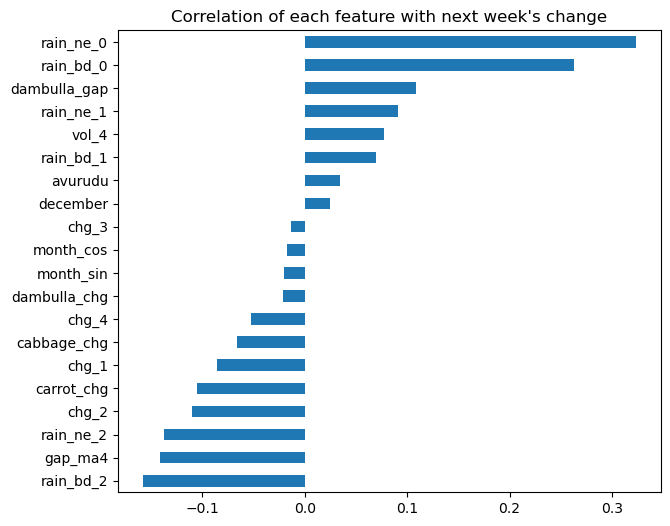

rain_bd_2      -0.158
gap_ma4        -0.141
rain_ne_2      -0.138
chg_2          -0.110
carrot_chg     -0.105
chg_1          -0.085
cabbage_chg    -0.066
chg_4          -0.053
dambulla_chg   -0.021
month_sin      -0.021
month_cos      -0.017
chg_3          -0.014
december        0.025
avurudu         0.035
rain_bd_1       0.070
vol_4           0.077
rain_ne_1       0.091
dambulla_gap    0.108
rain_bd_0       0.262
rain_ne_0       0.323
dtype: float64

In [30]:
corr = feat[feature_cols].corrwith(feat["target"]).sort_values()
corr.plot(kind="barh", figsize=(7, 6), title="Correlation of each feature with next week's change")
plt.show()
corr.round(3)

**What this shows:**
- This week's rain is the strongest link (`rain_ne_0` +0.32, `rain_bd_0` +0.26): heavy rain in the growing areas is followed by a price rise the next week.
- Rain from 2 weeks ago is negative (about −0.14 to −0.16): roughly 3 weeks after the rain, prices fall back as supply recovers.
- `gap_ma4` is negative (−0.14): when the price is above its 4-week average, it tends to fall the next week (mean reversion).
- `chg_1` and `chg_2` are negative: a rise is often followed by a partial fall.
- The calendar features are close to zero. Their effect is not a straight line, so tree models may still use them; feature importance in Step 6 will show whether they do.

Correlation only measures straight-line relationships, so this is a check, not a final answer.

In [31]:
feat.to_csv("dataset/features.csv")

## Step 4: Baseline models

Before building ensembles, I need simple baselines: scores that every ensemble has to beat. If an ensemble cannot beat them, it adds nothing.

1. **Naive:** next week's price = this week's price (predicted change = 0).
2. **Seasonal naive:** next week changes by the same % as the same week last year.
3. **Multiple linear regression:** a straight-line combination of the features (Lecture 2).
4. **Single decision tree:** the building block that bagging and boosting are made of.

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

feat = pd.read_csv("dataset/features.csv", index_col="date", parse_dates=True)
feature_cols = [c for c in feat.columns if c not in ["target", "price_now", "price_next"]]

train = feat[feat.index <= "2023-12-31"]
val   = feat[(feat.index > "2023-12-31") & (feat.index <= "2024-12-31")]
test  = feat[feat.index > "2024-12-31"]

X_train, y_train = train[feature_cols], train["target"]
X_val,   y_val   = val[feature_cols],   val["target"]
X_test,  y_test  = test[feature_cols],  test["target"]
print(X_train.shape, X_val.shape, X_test.shape)

(383, 20) (52, 20) (97, 20)


### How every model is scored

Models predict next week's % change. To report results in a way anyone understands, each predicted change is turned back into a price: `predicted price = this week's price × e^(predicted change)`, and compared with the real price next week.

- **RMSE (Rs/kg):** the main metric. It squares errors before averaging, so it punishes big misses (price spikes), which hurt traders most.
- **MAE (Rs/kg):** the average size of the error, easy to explain ("off by Rs 65/kg on average").
- **R² (on the % change):** the share of the week-to-week change the model explains. 0 means no better than predicting "no change"; below 0 means worse.
- **Train, validation and test** are scored separately. The test set is reported for every model but **never used to choose settings**, so the comparison stays honest.

Every result goes into one `results` list, which becomes the final comparison table in Step 9.

In [33]:
results = []

def score(part, pred_change):
    pred_price = part["price_now"] * np.exp(pred_change)
    return {
        "rmse": np.sqrt(mean_squared_error(part["price_next"], pred_price)),
        "mae": mean_absolute_error(part["price_next"], pred_price),
        "r2": r2_score(part["target"], pred_change),
    }

def add_result(name, pred_train, pred_val, pred_test, train_time=0.0):
    tr, va, te = score(train, pred_train), score(val, pred_val), score(test, pred_test)
    results.append({
        "model": name,
        "train_rmse": tr["rmse"], "val_rmse": va["rmse"], "test_rmse": te["rmse"],
        "test_mae": te["mae"], "train_r2": tr["r2"], "test_r2": te["r2"],
        "train_time_s": train_time,
    })

### Baselines 1 and 2: naive and seasonal naive

Neither needs training. The naive model always predicts a change of 0. The seasonal model copies the % change from the same week one year earlier; for the first year there is no previous year, so it falls back to 0 (the naive guess).

In [34]:
raw = pd.read_csv("dataset/weekly_with_rain.csv", index_col="date", parse_dates=True)
logp_all = np.log(raw["beans_pettah"])
seasonal = (logp_all.shift(51) - logp_all.shift(52)).reindex(feat.index).fillna(0)

add_result("Naive (no change)", np.zeros(len(train)), np.zeros(len(val)), np.zeros(len(test)))
add_result("Seasonal naive", seasonal.loc[train.index], seasonal.loc[val.index], seasonal.loc[test.index])

### Baseline 3: multiple linear regression

**One feature is left out for this model only:** `gap_ma4` is an exact combination of the three recent changes, `gap_ma4 = (3·chg_1 + 2·chg_2 + chg_3) / 4`, because the 4-week average is built from those same weeks. When one feature is an exact combination of others (**perfect multicollinearity**), linear regression cannot tell their effects apart: the coefficients become enormous (around 10¹²) with opposite signs that cancel out. Leaving `gap_ma4` out loses no information, because the linear model can rebuild it from `chg_1` to `chg_3`. The tree models keep all 20 features: a tree splits on one feature at a time, so a duplicated feature does not break it.

Features are scaled with `StandardScaler` (mean 0, standard deviation 1), as in Lecture 2's feature scaling, because rainfall is in mm (0-300) while price changes are small decimals; scaling makes the coefficients comparable. The scaler sits inside a `Pipeline`, so it learns the mean and standard deviation from the **training data only** and never sees validation or test data.

In [35]:
lin_cols = [c for c in feature_cols if c != "gap_ma4"]     # 19 features for linear regression

t0 = time.perf_counter()
linreg = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train[lin_cols], y_train)
t = time.perf_counter() - t0

add_result("Linear regression", linreg.predict(X_train[lin_cols]), linreg.predict(X_val[lin_cols]),
           linreg.predict(X_test[lin_cols]), t)

### Baseline 4: a single decision tree

Default settings, with no limit on depth, to see what one unrestricted tree does. Trees do not need scaling: they split on thresholds ("is rain above 60 mm?"), not distances.

In [36]:
t0 = time.perf_counter()
tree = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
t = time.perf_counter() - t0

add_result("Decision tree", tree.predict(X_train), tree.predict(X_val), tree.predict(X_test), t)
print("depth:", tree.get_depth(), " leaves:", tree.get_n_leaves(), " training rows:", len(X_train))

depth: 26  leaves: 383  training rows: 383


### Baseline results

In [37]:
res = pd.DataFrame(results).set_index("model")
res.round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.020
Decision tree,0.000,146.550,120.066,90.204,1.000,-0.035,0.033


**What the baselines show:**
- **Naive is a tough benchmark:** on the test set, "no change" is off by about Rs 107/kg (RMSE). Prices often stay near last week's level, so this is hard to beat.
- **Seasonal naive is much worse** (test RMSE about Rs 158). Copying last year's change does not work: price spikes depend on that year's rain and supply, not on a fixed yearly calendar.
- **Linear regression beats naive:** test RMSE about Rs 97 and MAE about Rs 66 (vs Rs 82 for naive), explaining about a third of the weekly change (R² ≈ 0.33). So the features carry real information.
- **The single decision tree overfits badly:** its training error is 0 (training R² = 1.00), but its test RMSE (about Rs 120) is worse than naive and its test R² is below 0. It grew to depth 26 with 383 leaves, one leaf for every training week, so it **memorised** the training data instead of learning patterns. This high variance is exactly what bagging (Step 5) is designed to fix.
- **Why training RMSE is lower for every model:** prices in the training years (2016-2023) were mostly much lower than in 2024-2026, so the same % error is fewer rupees. To judge overfitting fairly, compare R² (scale-free) or compare each model with the naive baseline in the same period.

**The bar to beat:** test RMSE ≈ Rs 97 (linear regression) and ≈ Rs 107 (naive).

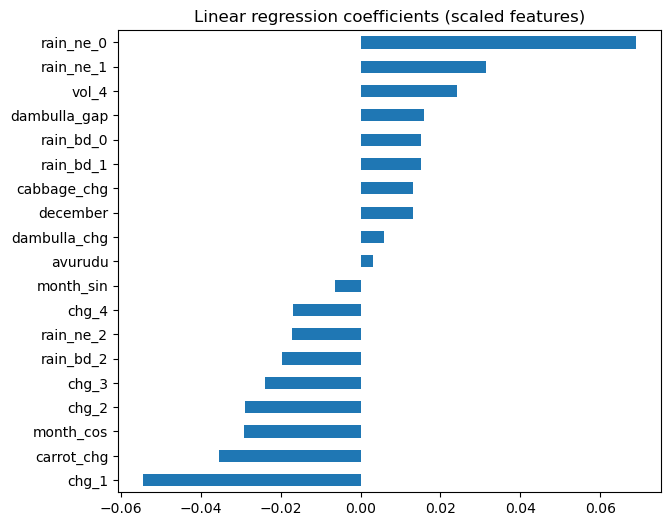

In [38]:
coef = pd.Series(linreg[-1].coef_, index=lin_cols).sort_values()
coef.plot(kind="barh", figsize=(7, 6), title="Linear regression coefficients (scaled features)")
plt.show()

**What the linear regression coefficients show:** because the features are scaled, larger bars mean stronger effects.
- **This week's Nuwara Eliya rain (`rain_ne_0`) has the largest positive effect**, and last week's rain there (`rain_ne_1`) is second: heavy rain in the growing area is followed by a price rise.
- **This week's price change (`chg_1`) has the largest negative effect**, and the earlier changes (`chg_2`, `chg_3`, `chg_4`) are negative too: when prices have just risen, they tend to fall back next week (**mean reversion**). Together these four do the job that `gap_ma4` did in the correlations of Step 3.
- **Rain from two weeks ago (`rain_ne_2`, `rain_bd_2`) is negative:** a few weeks after heavy rain, supply recovers and prices ease.
- This matches the correlations in Step 3.

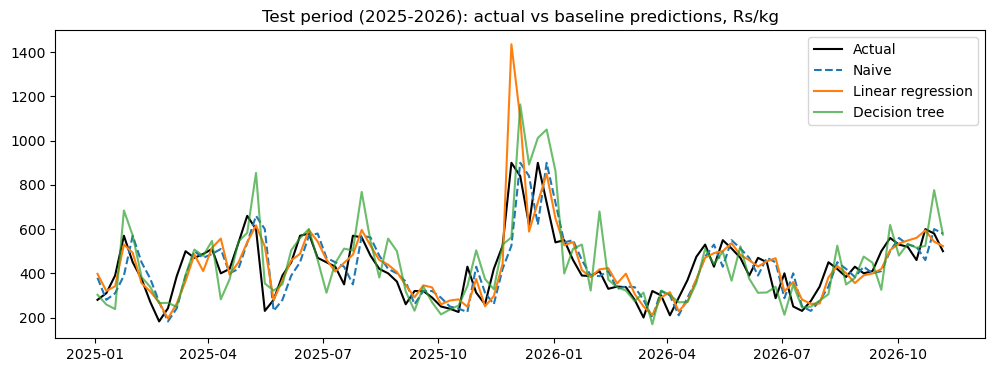

In [39]:
pred_price = lambda pred_change: test["price_now"] * np.exp(pred_change)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test["price_next"], color="black", linewidth=1.5, label="Actual")
ax.plot(test.index, test["price_now"], linestyle="--", label="Naive")
ax.plot(test.index, pred_price(linreg.predict(X_test[lin_cols])), label="Linear regression")
ax.plot(test.index, pred_price(tree.predict(X_test)), alpha=0.7, label="Decision tree")
ax.set_title("Test period (2025-2026): actual vs baseline predictions, Rs/kg")
ax.legend()
plt.show()

**What the chart shows:** the naive line is simply the actual price shifted one week later, so it is always one step behind every spike and every fall. linear regression follows the actual price more closely. The decision tree jumps around erratically, because each prediction copies a single memorised training week.

In [40]:
res.to_csv("results/results_step4_baselines.csv")

## Step 5: Bagging

The single decision tree memorised the training data (training error 0, test RMSE ≈ Rs 120): it has **high variance**, meaning small changes in the training data produce a very different tree. **Bagging** (bootstrap aggregating) fixes this:
1. draw many **bootstrap samples**: random samples of the training weeks, with replacement, each the same size as the training set;
2. grow one full tree on each sample;
3. **average** all the trees' predictions.

Each tree still overfits, but they overfit in *different* ways, so averaging cancels much of the noise.

**Out-of-bag (OOB) score:** each bootstrap sample leaves out about 37% of the weeks. Each week can be predicted by only the trees that never saw it, giving a free validation score without a separate dataset (`oob_score=True`).

In [41]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance

oob = {}   # OOB predictions in Rs, per model

def oob_rmse(model):
    pred_price = train["price_now"] * np.exp(model.oob_prediction_)
    return np.sqrt(mean_squared_error(train["price_next"], pred_price))

### Bagging with decision trees

300 full-depth trees, each trained on its own bootstrap sample of the 383 training weeks.

In [42]:
t0 = time.perf_counter()
bag = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=300,
                       oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0

add_result("Bagging (300 trees)", bag.predict(X_train), bag.predict(X_val), bag.predict(X_test), t)
oob["Bagging (300 trees)"] = (bag.oob_score_, oob_rmse(bag))

### Random Forest

Random Forest is bagging plus one extra idea: at each split, a tree may only choose from a **random subset of the features**. This stops every tree from splitting on the same strongest feature, so the trees become less alike (decorrelated), and averaging less-alike trees cancels more noise.

`max_features` controls the subset size. In scikit-learn the regression default is 1.0 (all features), which makes it almost identical to bagging, so two versions are trained:
- **Random Forest (all features)**: the scikit-learn default;
- **Random Forest (sqrt)**: √20 ≈ 4 random features per split, the classic Random Forest setting.

In [43]:
t0 = time.perf_counter()
rf = RandomForestRegressor(n_estimators=500, oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Random Forest (all features)", rf.predict(X_train), rf.predict(X_val), rf.predict(X_test), t)
oob["Random Forest (all features)"] = (rf.oob_score_, oob_rmse(rf))

t0 = time.perf_counter()
rf_sqrt = RandomForestRegressor(n_estimators=500, max_features="sqrt", oob_score=True,
                                random_state=42, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Random Forest (sqrt)", rf_sqrt.predict(X_train), rf_sqrt.predict(X_val), rf_sqrt.predict(X_test), t)
oob["Random Forest (sqrt)"] = (rf_sqrt.oob_score_, oob_rmse(rf_sqrt))

### Results so far

In [44]:
res = pd.DataFrame(results).set_index("model")
res.round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.020
Decision tree,0.000,146.550,120.066,90.204,1.000,-0.035,0.033
Bagging (300 trees),19.966,96.331,87.573,69.658,0.872,0.324,5.365
Random Forest (all features),20.199,94.966,87.845,69.776,0.871,0.320,3.310
Random Forest (sqrt),20.034,97.969,90.688,69.834,0.877,0.298,1.597


**What this shows:**
- **Bagging fixes the single tree's overfitting:** test RMSE falls from about Rs 120 (one tree) to about Rs 88 (300 bagged trees). Same kind of tree, same data; the only difference is averaging.
- **All bagging models beat both baselines on RMSE:** about Rs 88-90, compared with Rs 97 for linear regression and Rs 107 for naive.
- **But not on MAE:** linear regression's average error (about Rs 66) is still slightly lower than the forests' (about Rs 70). RMSE punishes big misses, so the forests are better at the large price spikes but slightly worse on ordinary weeks. Which model is "best" depends on whether big misses or typical misses matter more; for traders, big spikes are the costly ones, so RMSE stays the main metric.
- **The trees still memorise:** training RMSE is only about Rs 20 (training R² ≈ 0.87, test R² ≈ 0.3). Each full-depth tree overfits, but averaging stops this from hurting the test score.
- **Random feature subsets (sqrt) did not help here:** test RMSE about Rs 90 vs Rs 88 with all features. With only 20 features and one dominant feature (this week's Nuwara Eliya rain), forcing most splits to ignore it costs more than decorrelating the trees gains. Random Forest's trick helps most when there are many useful features.
- **Training time** stays small (a few seconds at most), because the dataset is small. Bagging is the slowest because it grows 300 full-depth trees.

### What the out-of-bag (OOB) score showed

The OOB score is compared with the real validation and test scores to see whether it was a good estimate.

In [45]:
oob_table = pd.DataFrame(oob, index=["OOB R²", "OOB RMSE (Rs)"]).T
oob_table["Test R²"] = res.loc[oob_table.index, "test_r2"]
print("Naive RMSE on the same training weeks: Rs", round(res.loc["Naive (no change)", "train_rmse"], 1))
oob_table.round(3)

Naive RMSE on the same training weeks: Rs 55.1


,OOB R²,OOB RMSE (Rs),Test R²
Bagging (300 trees),0.044,53.138,0.324
Random Forest (all features),0.040,53.044,0.320
Random Forest (sqrt),0.086,52.531,0.298


In [46]:
rf_oob = pd.Series(rf.oob_prediction_, index=train.index)
for start, end in [("2016", "2019"), ("2020", "2021"), ("2022", "2023")]:
    part = train.loc[start:end]
    print(f"{start}-{end}: OOB R² = {r2_score(part['target'], rf_oob.loc[start:end]):.2f}")

2016-2019: OOB R² = -0.01
2020-2021: OOB R² = 0.03
2022-2023: OOB R² = 0.12


**What the OOB score showed:** I expected the OOB score to be **too optimistic**, because bootstrap samples mix weeks from different years, so a tree can learn from 2023 and be scored on 2018 (using the future). The opposite happened: OOB R² is only about 0.04-0.09, much **lower** than the test R² (about 0.3), and OOB RMSE (about Rs 52-53) is only slightly better than naive on the same weeks (Rs 55).

Two reasons, both visible in the data:
1. **Little leakage in this target:** the target is the week-to-week % change, which has almost no long-term memory. Seeing a 2023 week tells the model little about a 2018 week, so mixing years leaks very little.
2. **The relationships got stronger over time:** split by period, OOB R² is about −0.01 in 2016-2019, 0.03 in 2020-2021 and 0.12 in 2022-2023. Before 2022 the features explain almost nothing; afterwards, with tighter supply and higher prices, rain and market signals matter more. The test period (2025-2026) is like the later years, so it scores higher.

**Lesson:** the OOB score assumes all training weeks behave the same way. When the relationship changes over time, a time-ordered validation set is the more trustworthy guide, which is why tuning (Step 7) uses `TimeSeriesSplit`.

### How many trees are enough?

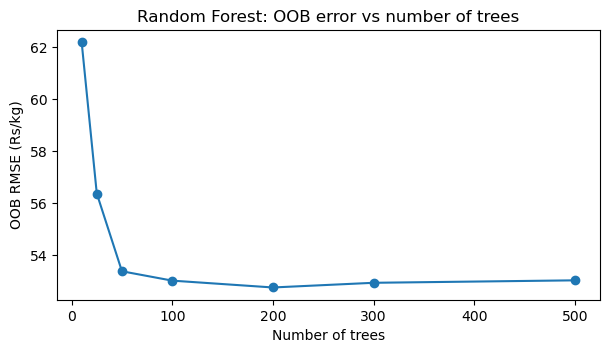

,trees,oob_rmse
0,10,62.2
1,25,56.4
2,50,53.4
3,100,53.0
4,200,52.8
5,300,52.9
6,500,53.0


In [47]:
curve = []
rf_grow = RandomForestRegressor(n_estimators=10, oob_score=True, warm_start=True, random_state=42, n_jobs=-1)
for n in [10, 25, 50, 100, 200, 300, 500]:
    rf_grow.set_params(n_estimators=n)
    rf_grow.fit(X_train, y_train)
    curve.append((n, oob_rmse(rf_grow)))
curve = pd.DataFrame(curve, columns=["trees", "oob_rmse"])

plt.figure(figsize=(7, 3.5))
plt.plot(curve["trees"], curve["oob_rmse"], marker="o")
plt.xlabel("Number of trees")
plt.ylabel("OOB RMSE (Rs/kg)")
plt.title("Random Forest: OOB error vs number of trees")
plt.show()
curve.round(1)

**What this shows:** the OOB error drops quickly from 10 to about 100 trees (about Rs 62 to Rs 53) and then stays flat. Adding trees reduces variance up to a point; after that, extra trees only cost time. Importantly, **more trees never make a Random Forest overfit**: the curve does not rise again. 500 trees is safely past the flat point.

### Feature importance

Two ways to measure it:
- **Impurity-based importance** (built into the forest): how much each feature reduced error inside the training data. It is fast but measured on data the trees have already seen, and it favours features with many different values.
- **Permutation importance** (on the 2024 validation data): shuffle one feature and measure how much worse the predictions get. If shuffling it hurts, the model really relies on it for **unseen** weeks.

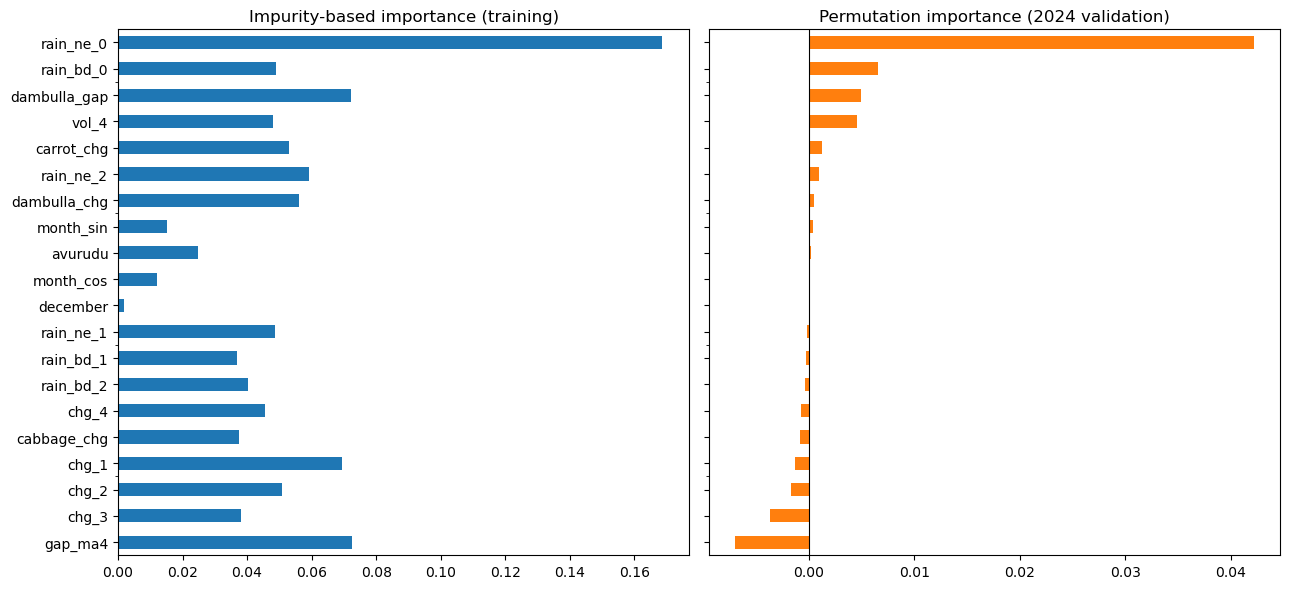

In [48]:
imp = pd.DataFrame({
    "impurity (training)": pd.Series(rf.feature_importances_, index=feature_cols),
    "permutation (validation)": pd.Series(
        permutation_importance(rf, X_val, y_val, n_repeats=20, random_state=42,
                               scoring="neg_root_mean_squared_error", n_jobs=-1).importances_mean,
        index=feature_cols),
}).sort_values("permutation (validation)")

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
imp["impurity (training)"].plot(kind="barh", ax=axes[0], title="Impurity-based importance (training)")
imp["permutation (validation)"].plot(kind="barh", ax=axes[1], color="tab:orange",
                                     title="Permutation importance (2024 validation)")
axes[1].axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**What the importances show:**
- **This week's Nuwara Eliya rain (`rain_ne_0`) is the most important feature by both measures**, far ahead of the rest on validation data. This matches Step 2 (rain one week before the price change) and the linear regression coefficients: rain in the growing areas is the strongest signal for next week's price.
- **Badulla rain, the Dambulla-Pettah price gap and recent volatility (`vol_4`)** also help on unseen weeks.
- **The two measures disagree on the price-history features** (`chg_1` to `chg_4`, `gap_ma4`). The forest uses them a lot inside the training data, but on 2024 data shuffling them slightly *improves* predictions (negative permutation importance). So the trees learned mean-reversion patterns from 2016-2023 that did not hold in 2024; this is part of why the training error (Rs 20) is so much lower than the validation error.
- **Calendar features matter little** on their own; festival effects partly show up through the price and rain features instead.

This is why permutation importance on held-out data is the more trustworthy measure.

In [49]:
res.to_csv("results/results_step5_bagging.csv")

## Step 6: Boosting

Bagging grows trees **independently** and averages them, which reduces **variance**. Boosting grows trees **one after another**: each new tree is trained on the errors the previous trees still make, so the model gradually fixes what it gets wrong. This reduces **bias** (underfitting), but because it keeps chasing errors, it can also start fitting noise, so it needs careful settings.

The three main settings:
- **`n_estimators`**: how many trees are added in sequence. Too few underfits; too many starts fitting noise.
- **`learning_rate`**: how much each new tree is allowed to correct. Smaller steps are more careful but need more trees.
- **`max_depth`**: how complex each tree is. Boosting works best with small, simple trees ("weak learners"), each fixing a little.

Three implementations are compared: scikit-learn's **Gradient Boosting**, **XGBoost** and **CatBoost**. LightGBM was also tried, but on this Windows/Anaconda setup its compiled library crashes the Python kernel when building its dataset. The brief asks for LightGBM *or* CatBoost, so CatBoost is used.

In [50]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)     # hide library version notices
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.ensemble import GradientBoostingRegressor, BaggingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

def val_rmse_rs(pred_change):
    return score(val, pred_change)["rmse"]

### Learning rate vs number of trees

Gradient Boosting is trained with 600 trees at three learning rates, and the validation (2024) error is measured after every tree using `staged_predict`.

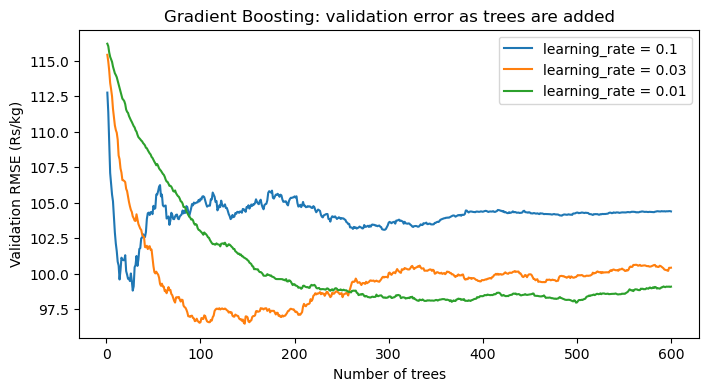

,best number of trees,best val RMSE,val RMSE at 600 trees
0.10,28.0,98.8,104.4
0.03,147.0,96.5,100.4
0.01,499.0,98.0,99.1


In [51]:
curves = {}
for lr in [0.1, 0.03, 0.01]:
    gb_lr = GradientBoostingRegressor(n_estimators=600, learning_rate=lr, max_depth=3,
                                      subsample=0.8, random_state=42).fit(X_train, y_train)
    curves[lr] = [val_rmse_rs(p) for p in gb_lr.staged_predict(X_val)]

plt.figure(figsize=(8, 4))
for lr, c in curves.items():
    plt.plot(range(1, 601), c, label=f"learning_rate = {lr}")
plt.xlabel("Number of trees")
plt.ylabel("Validation RMSE (Rs/kg)")
plt.title("Gradient Boosting: validation error as trees are added")
plt.legend()
plt.show()

pd.DataFrame({lr: {"best number of trees": int(np.argmin(c)) + 1, "best val RMSE": min(c), "val RMSE at 600 trees": c[-1]}
              for lr, c in curves.items()}).T.round(1)

**What this shows:**
- **learning_rate = 0.1** reaches its best validation error after only about 30 trees, then gets steadily **worse** as more trees are added (about Rs 99 → Rs 104): each big step starts fitting noise. This is boosting overfitting.
- **learning_rate = 0.03** reaches a slightly better best (about Rs 96-97) after about 150 trees and degrades much more slowly.
- **learning_rate = 0.01** needs about 500 trees to reach a similar level.

Smaller learning rates are more forgiving but slower. **0.03 is a good balance** and is used for all four models below. Unlike Random Forest (where more trees never hurt), boosting needs the number of trees **chosen carefully**.

### How deep should each tree be?

In [52]:
depth_rows = []
for d in [2, 3, 4, 6]:
    m = GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=d,
                                  subsample=0.8, random_state=42).fit(X_train, y_train)
    depth_rows.append({"max_depth": d,
                       "train RMSE": score(train, m.predict(X_train))["rmse"],
                       "val RMSE": val_rmse_rs(m.predict(X_val))})
pd.DataFrame(depth_rows).set_index("max_depth").round(1)

,train RMSE,val RMSE
max_depth,,
2,39.0,99.0
3,31.6,97.4
4,23.7,99.8
6,10.0,98.4


**What this shows:** deeper trees cut the **training** error sharply (about Rs 39 at depth 2 → Rs 10 at depth 6), but the **validation** error barely changes (about Rs 97-100). The extra depth only memorises the training weeks. **max_depth = 3** gives the best validation score with simple trees, so it is used below.

### Training the three boosting models

All three use `learning_rate = 0.03` and trees of depth 3. The number of trees is chosen by **early stopping**: trees are added up to a limit of 1,000, and training stops when the **2024 validation** error has not improved for 50 rounds. Early stopping uses the validation set, never the test set, so the test score stays honest.

`subsample = 0.8` trains each tree on a random 80% of the weeks, a small dose of bagging inside boosting that makes it less likely to fit noise.

In [53]:
n_trees = {}

# scikit-learn Gradient Boosting: find the best number of trees on validation, then refit
gb_search = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3,
                                      subsample=0.8, random_state=42).fit(X_train, y_train)
best_n = int(np.argmin([mean_squared_error(y_val, p) for p in gb_search.staged_predict(X_val)])) + 1
t0 = time.perf_counter()
gb = GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.03, max_depth=3,
                               subsample=0.8, random_state=42).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Gradient Boosting", gb.predict(X_train), gb.predict(X_val), gb.predict(X_test), t)
n_trees["Gradient Boosting"] = best_n

In [54]:
t0 = time.perf_counter()
xgb = XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, early_stopping_rounds=50, random_state=42)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
t = time.perf_counter() - t0
add_result("XGBoost", xgb.predict(X_train), xgb.predict(X_val), xgb.predict(X_test), t)
n_trees["XGBoost"] = xgb.best_iteration + 1

In [55]:
t0 = time.perf_counter()
cat = CatBoostRegressor(iterations=1000, learning_rate=0.03, depth=3, random_seed=42, verbose=0,
                        od_type="Iter", od_wait=50, use_best_model=True)
cat.fit(X_train, y_train, eval_set=(X_val, y_val))
t = time.perf_counter() - t0
add_result("CatBoost", cat.predict(X_train), cat.predict(X_val), cat.predict(X_test), t)
n_trees["CatBoost"] = cat.get_best_iteration() + 1

### For comparison: XGBoost with its default settings

XGBoost's defaults are 100 trees of depth 6 with a learning rate of 0.3, much more aggressive than the settings above.

In [56]:
t0 = time.perf_counter()
xgb_default = XGBRegressor(random_state=42).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("XGBoost (default settings)", xgb_default.predict(X_train), xgb_default.predict(X_val), xgb_default.predict(X_test), t)

In [57]:
res = pd.DataFrame(results).set_index("model")
print("Trees chosen by early stopping:", n_trees)
res.round(3)

Trees chosen by early stopping: {'Gradient Boosting': 152, 'XGBoost': 147, 'CatBoost': 233}


,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.020
Decision tree,0.000,146.550,120.066,90.204,1.000,-0.035,0.033
Bagging (300 trees),19.966,96.331,87.573,69.658,0.872,0.324,5.365
Random Forest (all features),20.199,94.966,87.845,69.776,0.871,0.320,3.310
Random Forest (sqrt),20.034,97.969,90.688,69.834,0.877,0.298,1.597
Gradient Boosting,34.445,96.585,85.533,67.325,0.635,0.346,0.913
XGBoost,35.639,96.828,89.009,68.686,0.595,0.340,0.218


### Is the difference between models real? A check with different random seeds

Both Gradient Boosting (`subsample=0.8`) and bagging use randomness, so their scores change slightly with the random seed. Each is retrained with 10 different seeds (same settings) to see how much the test RMSE moves just by chance. This is only a check of variability, not used to choose any model.

In [58]:
seed_rows = []
for s in range(10):
    g = GradientBoostingRegressor(n_estimators=n_trees["Gradient Boosting"], learning_rate=0.03, max_depth=3,
                                  subsample=0.8, random_state=s).fit(X_train, y_train)
    b = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=300,
                         random_state=s, n_jobs=-1).fit(X_train, y_train)
    seed_rows.append({"seed": s, "Gradient Boosting": score(test, g.predict(X_test))["rmse"],
                      "Bagging": score(test, b.predict(X_test))["rmse"]})
seeds = pd.DataFrame(seed_rows).set_index("seed")
seeds.agg(["mean", "std", "min", "max"]).round(1)

,Gradient Boosting,Bagging
mean,87.8,88.1
std,1.2,0.6
min,86.3,86.6
max,89.6,89.0


**What this shows:**
- **With the main seed (42), Gradient Boosting has the best test RMSE so far: about Rs 85.5** (MAE about Rs 67, test R² about 0.35), ahead of bagging and Random Forest (about Rs 88).
- **But the seed check shows this is partly luck:** over 10 seeds, Gradient Boosting averages about Rs 87.8 (range about Rs 86-90) and bagging about Rs 88.1 (range about Rs 87-89). On average the two are **essentially tied**, and differences of 1-3 Rs between models are within random variation on 97 test weeks. Bagging is also more stable from seed to seed.
- **XGBoost (about Rs 89) and CatBoost (about Rs 91)** land close to bagging. They add regularisation that scikit-learn's Gradient Boosting does not (XGBoost samples 80% of the features per tree; CatBoost uses symmetric trees and an L2 penalty), which makes them a little more cautious here. All boosting models still beat linear regression (Rs 97) and naive (Rs 107) on RMSE.
- **Why boosting did not clearly beat bagging:** boosting's strength is reducing bias by finding more and more detailed patterns. But week-to-week price changes are very noisy, and most of the learnable signal comes from a few strong features (mainly this week's Nuwara Eliya rain), which bagging already captures. Beyond that, there is mostly noise for boosting to chase.
- **Boosting overfits less than bagging, as configured:** training RMSE is about Rs 34-43 (training R² ≈ 0.4-0.6) versus Rs 20 (R² ≈ 0.87) for the bagged full-depth trees. Shallow trees, a small learning rate and early stopping keep it from memorising, yet the test score is about the same, which again suggests little extra signal is left.
- **Defaults overfit, and it costs accuracy:** XGBoost with default settings (depth 6, learning rate 0.3) memorised the training data (training RMSE ≈ Rs 0.2, R² ≈ 1.00), and its test RMSE (about Rs 95) is clearly worse than the tuned XGBoost (about Rs 89). This is the boosting version of the single tree's overfitting in Step 4.
- **The libraries behave similarly** on this small dataset (383 rows, numeric features only). Their speed and categorical-data advantages matter on much larger datasets.
- **Early stopping picked about 150-230 trees**, consistent with the learning-rate experiment.

The settings here were chosen on one validation year (2024). Step 7 tunes them more thoroughly with time-series cross-validation.


In [59]:
res.to_csv("results/results_step6_boosting.csv")

## Step 7: Stacking and voting

Bagging and boosting each combine many copies of **one kind** of model. Stacking and voting combine **different kinds** of models, hoping that their mistakes cancel out:
- **Voting** simply averages the base models' predictions, giving each one equal weight.
- **Stacking** trains a second-level model (the **meta-model**) that learns *how much to trust each base model*, using predictions the base models made on data they had not seen.

Combining only helps if the base models make **different** mistakes, so the base models are chosen for variety:
- three tree ensembles from Steps 5-6: **Random Forest**, **Gradient Boosting**, **XGBoost**;
- two very different model families: **SVR** (support vector regression, which fits a smooth curve) and **KNN** (k-nearest neighbours, which predicts from the most similar past weeks).

SVR and KNN work with **distances** between weeks, so their features must be scaled (`StandardScaler`); otherwise rainfall in mm (0-300) would swamp the small % changes.

In [60]:
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.model_selection import KFold

### The two new base models on their own

Each has one main setting, chosen on the 2024 validation data:
- **SVR `epsilon`:** errors smaller than epsilon are ignored. Too small and SVR chases noise; too large and it ignores real moves.
- **KNN `n_neighbors`:** how many similar past weeks to average. Too few copies noise; too many blurs everything into the average.

`weights="distance"` makes closer (more similar) weeks count more.

In [61]:
svr_rows = {eps: val_rmse_rs(make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=eps)).fit(X_train, y_train).predict(X_val))
            for eps in [0.02, 0.05, 0.1, 0.2, 0.3]}
knn_rows = {k: val_rmse_rs(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights="distance")).fit(X_train, y_train).predict(X_val))
            for k in [5, 10, 15, 25]}
best_eps = min(svr_rows, key=svr_rows.get)
best_k = min(knn_rows, key=knn_rows.get)
print("SVR validation RMSE by epsilon:", {k: round(float(v), 1) for k, v in svr_rows.items()}, "-> best", best_eps)
print("KNN validation RMSE by n_neighbors:", {k: round(float(v), 1) for k, v in knn_rows.items()}, "-> best", best_k)

SVR validation RMSE by epsilon: {0.02: 109.5, 0.05: 107.3, 0.1: 104.4, 0.2: 104.3, 0.3: 108.2} -> best 0.2
KNN validation RMSE by n_neighbors: {5: 103.4, 10: 102.0, 15: 101.8, 25: 108.0} -> best 15


In [62]:
t0 = time.perf_counter()
svr = make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=best_eps)).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("SVR", svr.predict(X_train), svr.predict(X_val), svr.predict(X_test), t)

t0 = time.perf_counter()
knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k, weights="distance")).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("KNN", knn.predict(X_train), knn.predict(X_val), knn.predict(X_test), t)

**What this shows:**
- **SVR** works best with `epsilon = 0.2` (validation RMSE about Rs 104): smaller values chase noise, larger ones ignore real moves. On the test set it scores about Rs 91.6 RMSE, but it has **the lowest MAE of any model so far (about Rs 65)**. As a smooth model it is very good on ordinary weeks but under-reacts to big spikes, which RMSE punishes.
- **KNN** works best with 15 neighbours (validation RMSE about Rs 102); 5 copies noise and 25 blurs everything. Its training error is exactly 0 because, with `weights="distance"`, each training week is its own nearest neighbour at distance zero, so it simply looks itself up. That is memorisation, not skill, and its test R² (about 0.19) is the lowest of the real models.

### The base models

The tree models reuse the settings chosen in Steps 5-6 (including the number of trees picked by early stopping).

In [63]:
base_models = [
    ("rf",  RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)),
    ("gb",  GradientBoostingRegressor(n_estimators=n_trees["Gradient Boosting"], learning_rate=0.03,
                                      max_depth=3, subsample=0.8, random_state=42)),
    ("xgb", XGBRegressor(n_estimators=n_trees["XGBoost"], learning_rate=0.03, max_depth=3,
                         subsample=0.8, colsample_bytree=0.8, random_state=42)),
    ("svr", make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=best_eps))),
    ("knn", make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k, weights="distance"))),
]

### Stacking

**How the meta-model is trained:** the training weeks are split into 5 parts. Each base model is trained on 4 parts and predicts the 5th, so every training week gets a prediction from models that never saw it. The meta-model learns from these honest predictions; if it learned from predictions on data the base models had memorised, it would trust the overfitting models far too much.

**Why `KFold(5)` and not `TimeSeriesSplit`:** stacking needs a prediction for *every* training week, but `TimeSeriesSplit` never predicts the earliest weeks, so scikit-learn refuses it ("cross_val_predict only works for partitions"). `KFold` without shuffling keeps each fold a continuous block of weeks, the closest option. The final test is still strictly on 2025-2026.

**Meta-model:** linear regression with `positive=True`, so each weight means "how much to trust this model" and cannot be negative. Negative weights would let the meta-model play correlated models off against each other, which overfits on only 383 weeks.

In [64]:
t0 = time.perf_counter()
stack = StackingRegressor(estimators=base_models, final_estimator=LinearRegression(positive=True),
                          cv=KFold(n_splits=5), n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Stacking (RF+GB+XGB+SVR+KNN)", stack.predict(X_train), stack.predict(X_val), stack.predict(X_test), t)

weights = pd.Series(stack.final_estimator_.coef_, index=[name for name, _ in base_models])
print("Meta-model weights:", {k: round(float(v), 3) for k, v in weights.items()}, " | sum:", round(float(weights.sum()), 2))

Meta-model weights: {'rf': 0.0, 'gb': 0.0, 'xgb': 0.326, 'svr': 0.429, 'knn': 0.0}  | sum: 0.76


**What the meta-model learned:** it gives weight to only **two** models, XGBoost (about 0.33) and SVR (about 0.43), and **zero** to Random Forest, Gradient Boosting and KNN.
- It keeps **one tree model** and drops the other two because the tree models make almost the same predictions (see the correlation table below), so a second or third one adds nothing new.
- It keeps **SVR** because SVR is a different kind of model whose errors differ from the trees'.
- The weights add up to only about 0.76, not 1. The meta-model is **shrinking** every prediction towards "no change": on the training years it found the base models' honest (out-of-fold) predictions only weakly reliable. This matches Step 5, where the relationships were much weaker before 2022 (OOB R² close to 0).

### Voting

The brief mentions **soft voting**, but soft voting averages predicted *class probabilities*, so it only exists for classification. For regression, `VotingRegressor` is the equivalent: it averages the five models' predictions with equal weights. Comparing it with stacking shows whether *learning* the weights beats *equal* weights.

In [65]:
t0 = time.perf_counter()
voting = VotingRegressor(estimators=base_models, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Voting (RF+GB+XGB+SVR+KNN)", voting.predict(X_train), voting.predict(X_val), voting.predict(X_test), t)

### How different are the base models?

Correlation between the base models' predictions on the 2024 validation weeks. Values near 1 mean two models make almost the same predictions, so combining them adds little.

In [66]:
base_preds = pd.DataFrame({name: m.predict(X_val) for (name, _), m in zip(base_models, voting.estimators_)})
base_preds.corr().round(2)

,rf,gb,xgb,svr,knn
rf,1.00,0.95,0.93,0.71,0.59
gb,0.95,1.00,0.97,0.72,0.54
xgb,0.93,0.97,1.00,0.70,0.56
svr,0.71,0.72,0.70,1.00,0.70
knn,0.59,0.54,0.56,0.70,1.00


**What this shows:** the three tree models are almost copies of each other (correlations 0.93-0.97): whether the trees are bagged or boosted matters much less than the fact that they are all trees using the same features. SVR (about 0.7 with the trees) and KNN (about 0.55-0.7) are the only real sources of variety. This is why the meta-model kept just one tree model.

### Results so far

In [67]:
res = pd.DataFrame(results).set_index("model")
res.round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.020
Decision tree,0.000,146.550,120.066,90.204,1.000,-0.035,0.033
Bagging (300 trees),19.966,96.331,87.573,69.658,0.872,0.324,5.365
Random Forest (all features),20.199,94.966,87.845,69.776,0.871,0.320,3.310
Random Forest (sqrt),20.034,97.969,90.688,69.834,0.877,0.298,1.597
Gradient Boosting,34.445,96.585,85.533,67.325,0.635,0.346,0.913
XGBoost,35.639,96.828,89.009,68.686,0.595,0.340,0.218


**What this shows:**
- **Voting beat stacking clearly:** voting's test RMSE is about Rs 86.7 (MAE about Rs 66, R² about 0.34), stacking's about Rs 91.5. Simply averaging five models did better than *learning* how to weight them.
- **Why learning the weights did worse:** the meta-model learned from only 383 noisy training weeks, mostly from years when the features explained very little (Step 5). So it learned to trust the models less (weights summing to about 0.76) and dropped three of them. In 2025-2026, when the relationships are stronger, that caution costs accuracy. Equal weights cannot overfit like this. Forecasters know this as the **forecast combination puzzle**: a simple average of forecasts often beats carefully estimated weights.
- **Voting works because of variety, not just numbers:** it combines the tree models (good at catching spikes) with SVR (steady on ordinary weeks), so it gets both a low RMSE (about Rs 86.7) and a low MAE (about Rs 66), one of the best combinations in the table.
- **Voting and Gradient Boosting are essentially tied** (about Rs 86.7 vs Rs 85.5). The seed check in Step 6 showed Gradient Boosting's score moves by about ±1-2 Rs with the random seed, so the difference is within noise. Averaging five different models is likely to be the more stable of the two.
- **Training time:** stacking is by far the slowest model so far (about 24 seconds in this run; between 15 and 60 seconds across runs on this laptop) because every base model is trained 6 times (5 folds plus the final fit), and it bought nothing here.

Both combination methods still beat linear regression (Rs 97) and naive (Rs 107).

In [68]:
res.to_csv("results/results_step7_stacking_voting.csv")

## Step 8: Hyperparameter tuning with time-series cross-validation

So far, settings were chosen by hand or on one validation year (2024). Here they are searched more systematically with `RandomizedSearchCV`, for the three strongest tree models: **Random Forest**, **Gradient Boosting** and **XGBoost**.

**Why randomized search:** it tries a fixed number of random combinations (30 per model) instead of every combination. With 4-7 settings per model, a full grid would be thousands of fits; random search usually finds settings almost as good for a small fraction of the time.

**Why `TimeSeriesSplit` instead of ordinary K-fold:** each fold trains only on weeks *before* the weeks it is tested on, exactly like real forecasting. Ordinary K-fold would mix past and future and give over-optimistic scores (and stratified K-fold is for classification, so it does not apply here).

**Which metric, and why:** RMSE (`neg_root_mean_squared_error`; scikit-learn maximises scores, so it uses the negative). RMSE punishes big misses, and for traders the costly mistakes are the big price spikes. It is computed on the target (the weekly % change in log price), so a CV RMSE of 0.25 means a typical error of roughly 25% in the weekly change. Only training weeks (2016-2023) are used; validation and test stay untouched.

In [69]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)
for k, (tr_idx, te_idx) in enumerate(tscv.split(X_train), 1):
    print(f"Fold {k}: train on {len(tr_idx)} weeks (to {X_train.index[tr_idx[-1]].date()}), "
          f"test on {len(te_idx)} weeks ({X_train.index[te_idx[0]].date()} to {X_train.index[te_idx[-1]].date()})")

Fold 1: train on 68 weeks (to 2017-12-15), test on 63 weeks (2017-12-22 to 2019-03-01)
Fold 2: train on 131 weeks (to 2019-03-01), test on 63 weeks (2019-03-08 to 2020-05-15)
Fold 3: train on 194 weeks (to 2020-05-15), test on 63 weeks (2020-05-22 to 2021-07-30)
Fold 4: train on 257 weeks (to 2021-07-30), test on 63 weeks (2021-08-06 to 2022-10-14)
Fold 5: train on 320 weeks (to 2022-10-14), test on 63 weeks (2022-10-21 to 2023-12-29)


### What is tuned, and why

| Model | Setting | Values tried | Why it matters |
|---|---|---|---|
| Random Forest | `max_depth` | None, 4, 6, 10, 20 | Limits how detailed each tree can get; full-depth trees memorised the training weeks in Step 5. |
| Random Forest | `min_samples_leaf` | 1, 3, 5, 10, 20 | Each prediction must average at least this many weeks, which smooths out one-off spikes. |
| Random Forest | `max_features` | 0.33, 0.5, 0.7, 1.0 | Share of features each split may consider; trades decorrelating the trees against access to the strongest feature (Step 5). |
| Gradient Boosting / XGBoost | `n_estimators` | 50-400 | How many correction rounds; too many starts fitting noise (Step 6). |
| Gradient Boosting / XGBoost | `learning_rate` | 0.01-0.1 | Size of each correction; smaller is safer but needs more trees. |
| Gradient Boosting / XGBoost | `max_depth` | 2, 3, 4 | Boosting works best with small, simple trees. |
| Gradient Boosting / XGBoost | `subsample` | 0.6, 0.8, 1.0 | Each tree sees a random share of the weeks, so it is less likely to fit noise. |
| Gradient Boosting | `min_samples_leaf` | 1, 5, 10, 20 | Stops leaves built on just one or two unusual weeks. |
| XGBoost | `colsample_bytree` | 0.6, 0.8, 1.0 | Each tree sees a random share of the features (more variety between trees). |
| XGBoost | `min_child_weight` | 1, 5, 10 | XGBoost's version of a minimum leaf size. |
| XGBoost | `reg_lambda` | 0.1, 1, 10 | Penalty on large leaf values (L2 regularisation), shrinking extreme predictions. |

**Not tuned:** the number of trees in Random Forest. Step 5 showed more trees never hurt a forest; they only add time, so the search uses 200 trees and the final model uses 500.

In [70]:
search_space = {
    "Random Forest": (
        RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1),
        {"max_depth": [None, 4, 6, 10, 20], "min_samples_leaf": [1, 3, 5, 10, 20],
         "max_features": [0.33, 0.5, 0.7, 1.0]}),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {"n_estimators": [50, 100, 150, 250, 400], "learning_rate": [0.01, 0.03, 0.05, 0.1],
         "max_depth": [2, 3, 4], "subsample": [0.6, 0.8, 1.0], "min_samples_leaf": [1, 5, 10, 20]}),
    "XGBoost": (
        XGBRegressor(random_state=42, n_jobs=1),
        {"n_estimators": [50, 100, 150, 250, 400], "learning_rate": [0.01, 0.03, 0.05, 0.1],
         "max_depth": [2, 3, 4], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
         "min_child_weight": [1, 5, 10], "reg_lambda": [0.1, 1, 10]}),
}

searches, best_params = {}, {}
for name, (estimator, grid) in search_space.items():
    t0 = time.perf_counter()
    s = RandomizedSearchCV(estimator, grid, n_iter=30, cv=tscv, scoring="neg_root_mean_squared_error",
                           random_state=42, n_jobs=-1).fit(X_train, y_train)
    searches[name], best_params[name] = s, s.best_params_
    print(f"{name}: best CV RMSE {-s.best_score_:.4f}  ({time.perf_counter() - t0:.0f} s)")
    print("   best settings:", s.best_params_)

Random Forest: best CV RMSE 0.2481  (39 s)
   best settings: {'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 10}
Gradient Boosting: best CV RMSE 0.2485  (31 s)
   best settings: {'subsample': 0.6, 'n_estimators': 50, 'min_samples_leaf': 10, 'max_depth': 2, 'learning_rate': 0.03}
XGBoost: best CV RMSE 0.2504  (4 s)
   best settings: {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


**What the search chose:** every model picked **cautious** settings:
- **Random Forest:** leaves of at least 10 weeks and depth limited to 10, so much smoother trees than the full-depth trees of Step 5.
- **Gradient Boosting:** only 50 trees of depth 2 at learning rate 0.03, using 60% of the weeks per tree. That is very little learning in total.
- **XGBoost:** depth 2, a strong L2 penalty (`reg_lambda = 10`), leaves of weight at least 5 and only 60% of the features per tree.

In other words, the search favoured models that stay close to "no change".

### Did tuning help? Cross-validation score before and after

The settings used in Steps 5-6 are scored with the same time-series folds, together with the naive "no change" guess as a reference.

In [71]:
untuned = {
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=n_trees["Gradient Boosting"], learning_rate=0.03,
                                                   max_depth=3, subsample=0.8, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=n_trees["XGBoost"], learning_rate=0.03, max_depth=3, subsample=0.8,
                            colsample_bytree=0.8, random_state=42),
}
cv_compare = pd.DataFrame({
    "CV RMSE (Steps 5-6 settings)": {n: -cross_val_score(m, X_train, y_train, cv=tscv,
                                                         scoring="neg_root_mean_squared_error").mean()
                                     for n, m in untuned.items()},
    "CV RMSE (tuned)": {n: -searches[n].best_score_ for n in untuned},
})
naive_cv = np.mean([np.sqrt(np.mean(y_train.iloc[te_idx] ** 2)) for _, te_idx in tscv.split(X_train)])
print(f"Naive (no change) CV RMSE: {naive_cv:.4f}")
cv_compare.round(4)

Naive (no change) CV RMSE: 0.2614


,CV RMSE (Steps 5-6 settings),CV RMSE (tuned)
Random Forest,0.2535,0.2481
Gradient Boosting,0.2583,0.2485
XGBoost,0.2566,0.2504


**What this shows:** tuning improved the cross-validation RMSE of all three models by about 2-4% (for example Gradient Boosting 0.258 → 0.249). But even the best tuned model is only about 5% better than the naive "no change" guess (0.261). Over the 2018-2023 test folds, the features explain very little, which matches the out-of-bag results in Step 5 (OOB R² close to 0 before 2022).

### Train the tuned models and score them on validation and test

In [72]:
tuned_models = {
    "Random Forest (tuned)": RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1,
                                                   **best_params["Random Forest"]),
    "Gradient Boosting (tuned)": GradientBoostingRegressor(random_state=42, **best_params["Gradient Boosting"]),
    "XGBoost (tuned)": XGBRegressor(random_state=42, **best_params["XGBoost"]),
}
for name, m in tuned_models.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    t = time.perf_counter() - t0
    add_result(name, m.predict(X_train), m.predict(X_val), m.predict(X_test), t)

res = pd.DataFrame(results).set_index("model")
res.loc[["Random Forest (all features)", "Random Forest (tuned)", "Gradient Boosting", "Gradient Boosting (tuned)",
         "XGBoost", "XGBoost (tuned)"]].round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Random Forest (all features),20.199,94.966,87.845,69.776,0.871,0.320,3.310
Random Forest (tuned),40.508,96.002,92.086,70.913,0.452,0.303,1.258
Gradient Boosting,34.445,96.585,85.533,67.325,0.635,0.346,0.913
Gradient Boosting (tuned),47.586,101.944,96.202,73.222,0.250,0.229,0.162
XGBoost,35.639,96.828,89.009,68.686,0.595,0.340,0.218
XGBoost (tuned),45.780,100.166,94.708,72.836,0.301,0.265,0.056


**What this shows: tuning made the test results worse.**
- Random Forest: about Rs 87.8 → Rs 92.1; Gradient Boosting: Rs 85.5 → Rs 96.2; XGBoost: Rs 89.0 → Rs 94.7. Validation (2024) scores also got worse for all three.
- The tuned models are much less overfitted (training R² dropped from about 0.6-0.87 to about 0.25-0.45), but they now **under-react**: they barely move away from "no change", so they miss the rain-driven price rises that matter most in 2024-2026.

**Why this happened:**
1. **The CV folds are mostly from the years when the signal was weak.** Four of the five folds test on 2017-2022, when the features explained almost nothing. There, the best strategy really is to learn very little, so the search rewarded cautious settings.
2. **The future looks different.** From 2022 onwards, and in the 2025-2026 test period, the relationships (especially rain → price) are stronger, so models that learned more do better.
3. **The CV differences are tiny.** The 2-4% improvements in CV RMSE are about the same size as the fold-to-fold noise, so the search is partly choosing on noise.

**Lesson:** hyperparameter tuning is only as good as how well the validation data resembles the future. Here, the single validation year closest to the test period (2024, used in Step 6) was a better guide than averaging over older folds. A possible improvement, not done here, would be to weight recent folds more or to use only recent folds.

**Decision:** the final comparison keeps the Step 5-6 settings. The tuned versions stay in the results table, so the comparison is complete and honest.

In [73]:
res.to_csv("results/results_step8_tuning.csv")

## Step 9: Hybrid model, Random Forest + ARIMA

The lecturer suggested combining a classical time-series model with a machine-learning model:
1. **ARIMA** models the price's own history: its trend, momentum and tendency to fall back after a jump. It looks only at past prices.
2. **Random Forest** then learns what ARIMA gets **wrong** (its errors, called *residuals*), using everything ARIMA cannot see: rain in the growing areas, the Dambulla market, other vegetables and the calendar.
3. **Final forecast = ARIMA forecast + Random Forest's predicted correction.**

Each part does what it is good at: ARIMA handles the smooth time pattern; the forest handles the shocks.

**ARIMA(p, d, q) in one line each:**
- **p**: how many past values the model looks back at (the autoregressive part);
- **d**: how many times the series is differenced. d = 1 models weekly *changes*, because the price level itself drifts (it more than doubled after 2022);
- **q**: how many past forecast errors it corrects for (the moving-average part).

ARIMA is fitted to the weekly **log** price on the training years only (2016-2023), for the same reason as before: price moves are proportional.

In [74]:
import warnings
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings("ignore")   # hide statsmodels convergence notices during the order search

log_price = np.log(raw["beans_pettah"])
log_price.index.freq = "W-FRI"
log_price_train = log_price[log_price.index <= "2023-12-31"]

### Choosing p and q

All combinations of p and q from 0 to 3 (with d = 1) are fitted, and the one with the lowest **AIC** (Akaike information criterion) is chosen. AIC rewards a good fit but penalises extra parameters, so it avoids needlessly complex models.

In [75]:
aic_rows = []
for p in range(4):
    for q in range(4):
        try:
            aic_rows.append({"p": p, "q": q, "AIC": ARIMA(log_price_train, order=(p, 1, q)).fit().aic})
        except Exception:
            pass
aic_table = pd.DataFrame(aic_rows).sort_values("AIC").reset_index(drop=True)
best_p, best_q = int(aic_table.loc[0, "p"]), int(aic_table.loc[0, "q"])
print(f"Chosen order: ARIMA({best_p}, 1, {best_q})")
aic_table.head(5).round(1)

Chosen order: ARIMA(1, 1, 1)


,p,q,AIC
0,1,1,16.6
1,1,2,18.5
2,2,1,18.5
3,3,3,19.1
4,3,1,20.5


**What the AIC table shows:** ARIMA(1,1,1) has the lowest AIC (about 16.6). The next models, (1,1,2) and (2,1,1), are about 2 points worse: adding a parameter did not improve the fit enough to pay for its extra complexity. So the simplest model with one AR and one MA term is used.

### ARIMA forecasts without looking ahead

The ARIMA parameters are learned on 2016-2023 only and then **frozen**. For every later week, the model makes a one-step-ahead forecast using only the prices up to that week, exactly as it would be used in real life (`apply` reuses the fitted parameters on the full series; it does not refit).

The ARIMA forecast of next week's change is `forecast of next week's log price − this week's log price`, the same scale as the target.

In [76]:
t0 = time.perf_counter()
arima = ARIMA(log_price_train, order=(best_p, 1, best_q)).fit()
arima_time = time.perf_counter() - t0
print(arima.params.round(3).to_dict())

one_step = arima.apply(log_price).predict()          # forecast of each week, made from the weeks before it
arima_change = (one_step.shift(-1) - log_price).reindex(feat.index)   # forecast of next week's change

add_result(f"ARIMA({best_p},1,{best_q})", arima_change.loc[train.index], arima_change.loc[val.index],
           arima_change.loc[test.index], arima_time)

{'ar.L1': 0.766, 'ma.L1': -0.965, 'sigma2': 0.06}


**What the ARIMA parameters mean:** the model works on weekly changes in log price. `ar.L1 = 0.77` would carry most of last week's change forward (momentum), but `ma.L1 = -0.97` almost cancels last week's unexpected jump. Together they make ARIMA forecast something close to a **smoothed recent level**: after a sudden spike it expects the price to drift partly back, and after a calm period it expects little change. This is a reasonable pattern for vegetable prices, but it uses no information beyond the price itself.

### The hybrid: Random Forest learns ARIMA's errors

The forest uses the same settings as in Step 5 (500 trees, all features), so the hybrid is not tuned on the test data. Its target is ARIMA's training error: `actual change − ARIMA forecast`.

In [77]:
arima_error_train = y_train - arima_change.loc[train.index]

t0 = time.perf_counter()
rf_residual = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X_train, arima_error_train)
t = time.perf_counter() - t0 + arima_time      # the hybrid needs both fits

hybrid = {part: arima_change.loc[data.index] + rf_residual.predict(X)
          for part, data, X in [("train", train, X_train), ("val", val, X_val), ("test", test, X_test)]}
add_result("Hybrid: RF + ARIMA", hybrid["train"], hybrid["val"], hybrid["test"], t)

res = pd.DataFrame(results).set_index("model")
res.loc[["Naive (no change)", f"ARIMA({best_p},1,{best_q})", "Random Forest (all features)",
         "Gradient Boosting", "Voting (RF+GB+XGB+SVR+KNN)", "Hybrid: RF + ARIMA"]].round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
"ARIMA(1,1,1)",53.685,111.057,101.485,75.028,0.087,0.114,0.150
Random Forest (all features),20.199,94.966,87.845,69.776,0.871,0.320,3.310
Gradient Boosting,34.445,96.585,85.533,67.325,0.635,0.346,0.913
Voting (RF+GB+XGB+SVR+KNN),25.095,96.818,86.742,66.059,0.810,0.338,3.850
Hybrid: RF + ARIMA,19.548,94.135,83.866,65.747,0.881,0.364,3.354


**What this shows:**
- **The hybrid is the best model so far on every test measure:** test RMSE about **Rs 83.9** (Gradient Boosting Rs 85.5, Voting Rs 86.7, Random Forest Rs 87.8), test R² about **0.36**, and test MAE about Rs 65.7, tied with SVR (Rs 65.4) for the lowest. It also has the best **validation** score (Rs 94.1), so the result is not just a lucky test year.
- **It beats both of its parts.** ARIMA alone is only about 5% better than the naive guess (Rs 101.5 vs Rs 107.4, R² 0.11): past prices on their own predict little. Random Forest alone gets Rs 87.8. Together they get Rs 83.9: ARIMA supplies the price's own momentum and pull-back, and the forest adds what ARIMA cannot see (rain, the other market, the season).
- **Caution on the size of the gain:** Rs 1.7 ahead of Gradient Boosting is about the size of the seed-to-seed variation found in Step 6 (about Rs 1). The hybrid is at least as good as the best ensembles, and slightly better, but not by a wide margin.
- **It still overfits the training weeks** (training RMSE about Rs 19.5 vs test Rs 83.9), like the Random Forest it contains, because the forest's full-depth trees memorise the training errors. Averaging 500 trees keeps this from harming the test score.

### What does the forest correct?

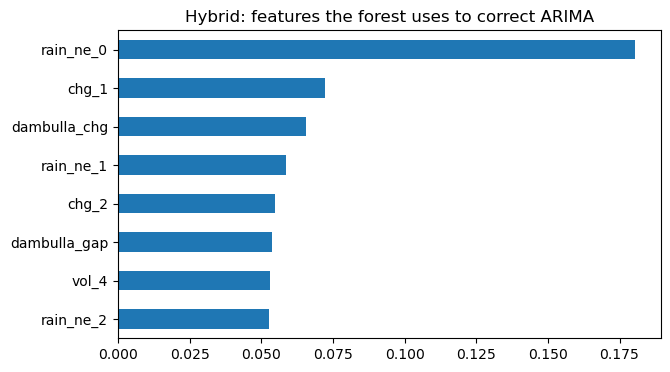

In [78]:
pd.Series(rf_residual.feature_importances_, index=feature_cols).sort_values().tail(8).plot(
    kind="barh", figsize=(7, 4), title="Hybrid: features the forest uses to correct ARIMA")
plt.show()

**What the forest corrects:**
- **This week's Nuwara Eliya rain (`rain_ne_0`) is by far the biggest correction**, about three times more important than any other feature. ARIMA looks only at past prices, so rain is exactly the information it is missing. It is also the top feature for the plain Random Forest (Step 5), so the forest is adding the same weather signal on top of ARIMA.
- **`chg_1`, last week's price change, comes second**, even though ARIMA already uses past prices. ARIMA reacts to every jump in the same fixed, linear way; the forest can react differently to small and large jumps, or to jumps during heavy rain.
- **`dambulla_chg` and `dambulla_gap`** (what the other main wholesale market did) are also used: another source of information outside ARIMA.

### The hybrid on the test period

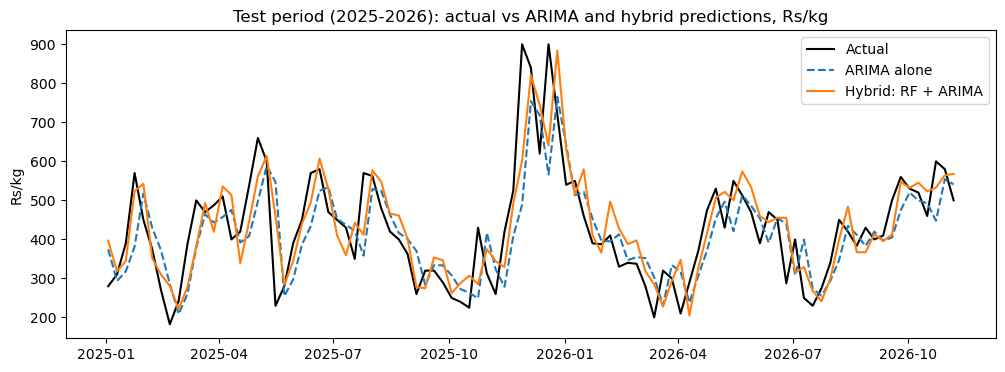

In [79]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test["price_next"], color="black", linewidth=1.5, label="Actual")
ax.plot(test.index, test["price_now"] * np.exp(arima_change.loc[test.index]), linestyle="--", label="ARIMA alone")
ax.plot(test.index, test["price_now"] * np.exp(hybrid["test"]), label="Hybrid: RF + ARIMA")
ax.set_title("Test period (2025-2026): actual vs ARIMA and hybrid predictions, Rs/kg")
ax.set_ylabel("Rs/kg")
ax.legend()
plt.show()

**What the chart shows:**
- **ARIMA alone (dashed) is mostly one week late.** It behaves like a smoothed version of the naive guess: it reacts to a rise or fall only after it has happened, and it never reaches the full height of a spike (for example the December 2025 peak near Rs 900/kg, where ARIMA stays around Rs 750).
- **The hybrid (orange) gets closer to the peaks and troughs**, because the forest adds the rain and Dambulla signals that ARIMA cannot see. In December 2025 it reaches about Rs 850-880.
- **It is still often late on sudden moves** (for example the sharp drop in May 2025). Weekly prices are driven partly by things no feature here measures (transport, festivals, supply shocks), so some error cannot be removed with this data.

In [80]:
res.to_csv("results/results_step9_hybrid.csv")

## Step 10: Final comparison of all models

Every model from Steps 4-9 is scored on exactly the same weeks, so they can be compared fairly. Columns in the table:
- **train / val / test RMSE (Rs/kg):** typical error on the training weeks (2016-2023), the validation year (2024) and the test period (2025-26).
- **unseen RMSE:** one RMSE over all **149 weeks the models never trained on** (52 validation + 97 test weeks), calculated from the two parts: √((52·val² + 97·test²) / 149).
- **test MAE / test R²:** average size of the test error in Rs, and how much of the week-to-week change the model explains.
- **overfit gap:** test RMSE minus training RMSE. A large gap means the model fits the training weeks much better than new weeks.
- **train time:** seconds to fit the final model once (the search time from Step 8 is not included).

### How the final model is chosen

By **unseen RMSE**, not by the test score alone:
- Picking the model with the best **test** score and then reporting that same score makes it look better than it really is: the test period would have been used for a decision, so it is no longer an independent check.
- Picking by the **validation year alone** (52 weeks) is too easily fooled by one lucky year; for example, default XGBoost has the best 2024 score of all (Rs 91.1) but memorised the training weeks and is one of the weaker models on 2025-26 (Rs 95.4).
- Using **both** unseen periods together (149 weeks) means a model has to do well across 2024, 2025 and 2026 to win.

In [81]:
final = pd.DataFrame(results).set_index("model")

# One RMSE over all 149 weeks the models never trained on: 2024 (validation) + 2025-26 (test)
n_val, n_test = len(val), len(test)
final["unseen_rmse"] = np.sqrt((n_val * final["val_rmse"]**2 + n_test * final["test_rmse"]**2) / (n_val + n_test))
final["overfit_gap"] = final["test_rmse"] - final["train_rmse"]

def family_of(name):
    if name.startswith("Hybrid"): return "Hybrid"
    if name.startswith(("Stacking", "Voting")): return "Stacking / voting"
    if name.startswith(("Bagging", "Random Forest")): return "Bagging"
    if name.startswith(("Gradient Boosting", "XGBoost", "CatBoost")): return "Boosting"
    if name.startswith(("SVR", "KNN", "ARIMA")): return "Single model"
    return "Baseline"

final.insert(0, "family", [family_of(m) for m in final.index])
final = final.sort_values("unseen_rmse")
final.to_csv("results/results_final.csv")

final[["family", "train_rmse", "val_rmse", "test_rmse", "unseen_rmse", "test_mae",
       "test_r2", "overfit_gap", "train_time_s"]].round(2)

,family,train_rmse,val_rmse,test_rmse,unseen_rmse,test_mae,test_r2,overfit_gap,train_time_s
model,,,,,,,,,
Hybrid: RF + ARIMA,Hybrid,19.55,94.14,83.87,87.59,65.75,0.36,64.32,3.35
Gradient Boosting,Boosting,34.45,96.59,85.53,89.55,67.32,0.35,51.09,0.91
Voting (RF+GB+XGB+SVR+KNN),Stacking / voting,25.10,96.82,86.74,90.39,66.06,0.34,61.65,3.85
Random Forest (all features),Bagging,20.20,94.97,87.85,90.39,69.78,0.32,67.65,3.31
Bagging (300 trees),Bagging,19.97,96.33,87.57,90.73,69.66,0.32,67.61,5.37
XGBoost,Boosting,35.64,96.83,89.01,91.81,68.69,0.34,53.37,0.22
CatBoost,Boosting,42.47,96.54,90.80,92.84,68.42,0.31,48.33,0.48
Random Forest (sqrt),Bagging,20.03,97.97,90.69,93.29,69.83,0.30,70.65,1.60
Random Forest (tuned),Bagging,40.51,96.00,92.09,93.47,70.91,0.30,51.58,1.26


**What the table shows:**
- **The RF + ARIMA hybrid ranks first** on unseen RMSE (about **Rs 87.6**), test RMSE (Rs 83.9) and test R² (0.36), and has the second-best validation score. It is chosen as the **final model**.
- **The next places are very close:** Gradient Boosting (Rs 89.6), Voting and Random Forest (both about Rs 90.4) and Bagging (Rs 90.7). The top five are within about Rs 3 of each other, while the naive guess is Rs 110.6. Several ensembles are clearly better than doing nothing, but the differences between them are small.
- **The worst models are the ones that do not average anything:** the single decision tree (Rs 129.9) and the seasonal naive guess (Rs 152.3).

### Test RMSE of every model

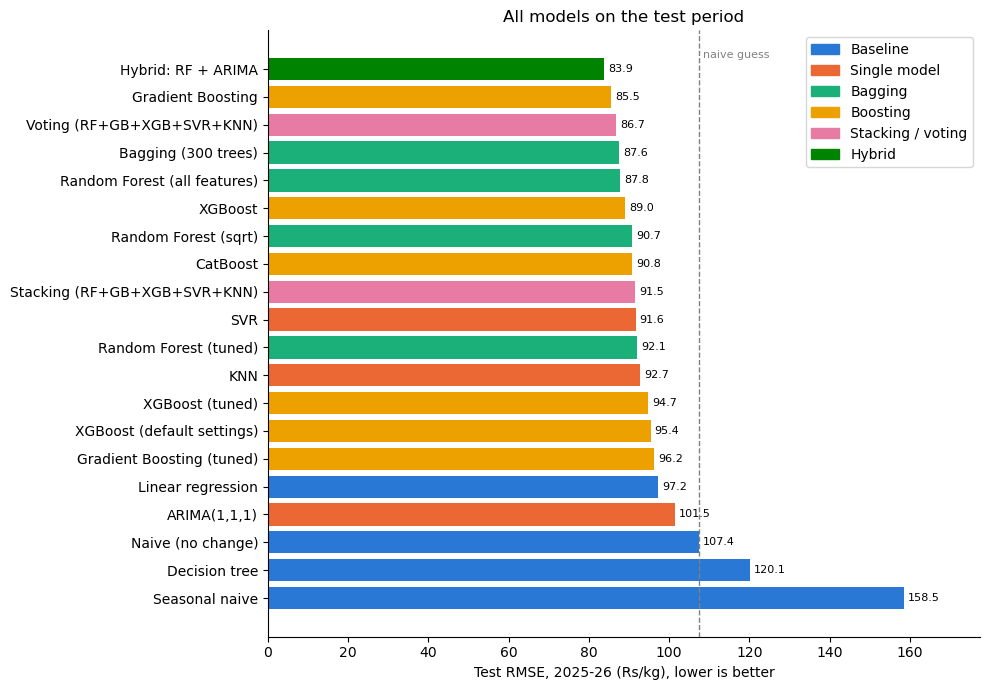

In [82]:
family_colors = {"Baseline": "#2a78d6", "Single model": "#eb6834", "Bagging": "#1baf7a",
                 "Boosting": "#eda100", "Stacking / voting": "#e87ba4", "Hybrid": "#008300"}
family_legend = [plt.Rectangle((0, 0), 1, 1, color=c) for c in family_colors.values()]
order = final.sort_values("test_rmse", ascending=False)      # best model at the top
naive_rmse = final.loc["Naive (no change)", "test_rmse"]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(order.index, order["test_rmse"], color=order["family"].map(family_colors))
for y, v in enumerate(order["test_rmse"]):
    ax.text(v + 1, y, f"{v:.1f}", va="center", fontsize=8)
ax.axvline(naive_rmse, color="grey", linestyle="--", linewidth=1)
ax.text(naive_rmse + 1, len(order) - 0.6, "naive guess", color="grey", fontsize=8)
ax.set_xlim(0, order["test_rmse"].max() * 1.12)
ax.set_xlabel("Test RMSE, 2025-26 (Rs/kg), lower is better")
ax.set_title("All models on the test period")
ax.legend(family_legend, family_colors.keys(), loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the chart shows:** the colours group the models by family. The **top of the chart is all ensembles** (hybrid, boosting, voting, bagging); the single models (SVR, KNN, ARIMA) and baselines are mostly at the bottom. Every ensemble beats the naive guess (dashed line, Rs 107.4); the single decision tree and the seasonal naive guess do not. **Both families do well:** the best bagging model (Rs 87.6) and the best boosting model (Rs 85.5) are only about Rs 2 apart.

### Training time

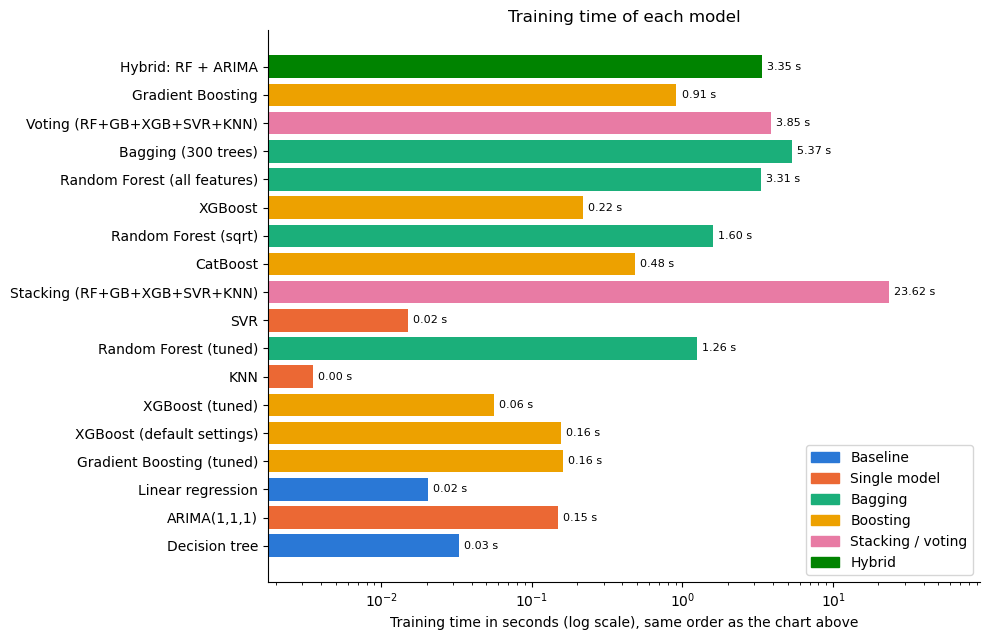

In [83]:
timed = order[order["train_time_s"] > 0]      # naive and seasonal naive need no training

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(timed.index, timed["train_time_s"], color=timed["family"].map(family_colors))
for y, v in enumerate(timed["train_time_s"]):
    ax.text(v * 1.08, y, f"{v:.2f} s", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlim(timed["train_time_s"].min() / 2, timed["train_time_s"].max() * 4)
ax.set_xlabel("Training time in seconds (log scale), same order as the chart above")
ax.set_title("Training time of each model")
ax.legend(family_legend, family_colors.keys(), loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the training times show:**
- **Every model trains in under a minute, most in a few seconds**, because the training set is small (383 weeks). Times also change from one run to the next on the same laptop (other programs running, first-call start-up), by a second or two for most models and by tens of seconds for stacking, so only large differences mean anything.
- **Stacking is clearly the slowest** (about 24 s in this run, and between 15 and 60 s across runs): every base model is trained 5 extra times to produce the cross-validated predictions for the meta-model. It was also less accurate than simple voting, so here the extra cost bought nothing.
- **Bagging with 300 full-depth trees** (about 5 s) and **voting** (about 4 s) come next: bagging grows hundreds of full-depth trees, and voting trains all five base models. Random Forest is faster than plain bagging because each split only looks at some of the features.
- **The boosting models and Random Forest are in the same range** (a few seconds). Boosting needs fewer, smaller trees (about 150 trees of depth 3), but has to build them one after another, while the forest builds its 500 trees in parallel on all CPU cores.
- **The hybrid costs about the same as one Random Forest:** fitting ARIMA takes well under a second.
- **Single models** (linear regression, one tree, SVR, KNN) train in well under 0.1 s, but they are less accurate.
- Speed does not decide the choice here; it would matter with much more data or frequent retraining.

### Overfitting: training vs test error

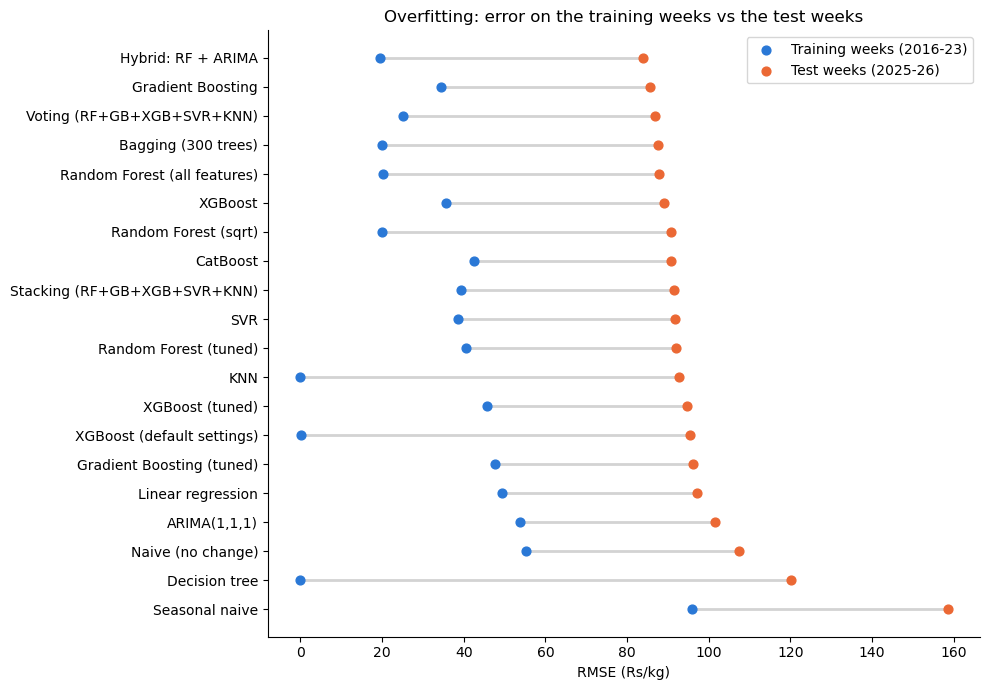

In [84]:
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(10, 7))
ax.hlines(y, order["train_rmse"], order["test_rmse"], color="lightgrey", linewidth=2)
ax.scatter(order["train_rmse"], y, color="#2a78d6", s=40, zorder=3, label="Training weeks (2016-23)")
ax.scatter(order["test_rmse"], y, color="#eb6834", s=40, zorder=3, label="Test weeks (2025-26)")
ax.set_yticks(y, order.index)
ax.set_xlabel("RMSE (Rs/kg)")
ax.set_title("Overfitting: error on the training weeks vs the test weeks")
ax.legend(loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the overfitting chart shows:**
- **Models that memorise the training weeks** (training error close to 0: the single decision tree, KNN and default XGBoost) all score worse on the test weeks than the ensembles. A perfect training score is a warning sign, not a good result.
- **A large gap is not automatically bad.** Random Forest, Bagging and the hybrid also fit the training weeks very closely (about Rs 20) but are among the best on the test weeks, because averaging hundreds of trees cancels most of the memorised noise.
- **Boosting with small steps and early stopping** (Gradient Boosting, XGBoost, CatBoost) keeps the gap smaller (training about Rs 35-42) and reaches a similar test score.
- **The tuned models** have the smallest gaps of the tree models but worse test scores (Step 8): making a model more cautious reduces overfitting, but in this case it also removed useful patterns.
- The training error is **not** a good guide to the test error; only scores on unseen weeks are.

### Results by test year

The test period is split into 2025 and 2026 to see whether the ranking holds in both years or depends on one of them. The test predictions of these models are also saved, so the Streamlit app can show actual vs predicted prices.

In [85]:
year_preds = {
    "Naive (no change)": np.zeros(len(test)),
    "Linear regression": linreg.predict(X_test[lin_cols]),
    "Random Forest (all features)": rf.predict(X_test),
    "Gradient Boosting": gb.predict(X_test),
    "Voting (RF+GB+XGB+SVR+KNN)": voting.predict(X_test),
    "Hybrid: RF + ARIMA": np.asarray(hybrid["test"]),
}

rows = {}
for name, pred in year_preds.items():
    pred = pd.Series(pred, index=test.index)
    rows[name] = {f"Test RMSE {y}": score(test[test.index.year == y], pred[test.index.year == y])["rmse"]
                  for y in (2025, 2026)}
by_year = pd.DataFrame(rows).T
print("Test weeks:", {y: int((test.index.year == y).sum()) for y in (2025, 2026)})

# predicted prices for the week each forecast is for (one week after the forecast is made)
test_pred = pd.DataFrame({name: test["price_now"] * np.exp(p) for name, p in year_preds.items()})
test_pred.insert(0, "actual", test["price_next"])
test_pred.index = test.index + pd.Timedelta(days=7)
test_pred.index.name = "week"
test_pred.round(1).to_csv("results/test_predictions.csv")

by_year.round(1)

Test weeks: {2025: 52, 2026: 45}


,Test RMSE 2025,Test RMSE 2026
Naive (no change),126.9,79.1
Linear regression,118.0,65.4
Random Forest (all features),100.9,69.8
Gradient Boosting,95.0,73.0
Voting (RF+GB+XGB+SVR+KNN),100.3,67.8
Hybrid: RF + ARIMA,96.3,66.7


**What the results by year show:**
- **2025 was a much harder year than 2026:** even the naive guess was off by Rs 127 in 2025 but only Rs 79 in 2026. 2025 had the biggest swings in the test period, including the jump to about Rs 900/kg in December 2025.
- **Every model beats the naive guess in both years**, so the improvement does not come from one lucky period.
- **The best model changes from year to year.** In 2025, Gradient Boosting was best (Rs 95.0); in 2026, linear regression was best (Rs 65.4). But Gradient Boosting was the weakest of these models in 2026 (Rs 73.0), and linear regression was by far the weakest in 2025 (Rs 118.0). Tree models help most in volatile periods with spikes; in a calmer year a simple linear model does just as well.
- **The hybrid is second in both years** (Rs 96.3 and Rs 66.7), the only model close to the top each time. Its overall first place comes from being consistent, not from one good year.
- With only about 50 weeks per year, a difference of a few rupees between models is not reliable; this supports choosing the final model on all unseen weeks together rather than on one period.

### Bagging vs boosting vs stacking (the Lecture 5 comparison)

The first five rows are the comparison from Lecture 5 (slide 17); the last two show what happened in this project.

| | Bagging | Boosting | Stacking |
|---|---|---|---|
| **Approach** | Parallel training of models, each on a bootstrap sample | Sequential training: each model corrects the errors of the ones before it | A meta-model learns how to combine the base models' predictions |
| **Base models** | Homogeneous (here: decision trees) | Homogeneous (here: small decision trees) | Can be heterogeneous (here: RF, Gradient Boosting, XGBoost, SVR, KNN) |
| **Subset selection** | Random sampling with replacement (Random Forest also picks random features at each split) | Not required (the models here also use 80% subsamples) | Not required |
| **Goal** | Reduce variance | Reduce bias | Reduce both |
| **How predictions are combined** | Averaging | Weighted sum of the trees (learning rate × each tree) | A trained model (here: linear regression with positive weights) |
| **Best model here (test RMSE)** | Bagging Rs 87.6, Random Forest Rs 87.8 | Gradient Boosting Rs 85.5, XGBoost Rs 89.0, CatBoost Rs 90.8 | Stacking Rs 91.5 (voting, the simple average, Rs 86.7) |
| **What happened** | Fixed the single tree's overfitting (Rs 120 → Rs 88) with no tuning | Matched bagging only with a small learning rate and early stopping; default XGBoost overfitted | Did worse than simple voting: the meta-model learned its weights from noisy, older weeks |

### Overall interpretation

**1. Bagging vs boosting.** Bagging (averaging independent full-depth trees) fixed the single tree's overfitting: test RMSE fell from Rs 120 to about Rs 88. Boosting (adding small trees one after another, each fixing the errors left so far) reached a similar level (Gradient Boosting about Rs 85.5). The 10-seed check in Step 6 showed that this gap is within the random variation, so **neither family is clearly better here**. The reason: weekly bean prices are mostly noise (even the best model explains about 36% of the weekly change), so the main problem is **variance** (fitting noise), which bagging is designed to reduce; boosting's strength, reducing **bias**, helps less. In practice, bagging worked well **without tuning** (more trees never hurt), while boosting needed a small learning rate and early stopping: default XGBoost overfitted (training RMSE 0.2, test Rs 95.4). On this small dataset both families train in a few seconds.

**Random Forest vs XGBoost** (the comparison the brief names): Random Forest has the lower test RMSE (Rs 87.8 vs Rs 89.0), XGBoost the slightly lower MAE (Rs 68.7 vs Rs 69.8) and higher R² (0.34 vs 0.32). That is effectively a tie, well within the seed-to-seed variation. The difference is in the effort: Random Forest worked with its default settings, while XGBoost needed a small learning rate (0.03), shallow trees (depth 3) and early stopping; with its default settings it overfitted (training RMSE 0.2, test Rs 95.4). For noisy weekly data like this, Random Forest is the safer choice; XGBoost's extra power only pays off when it is tuned carefully.

**2. The OOB score.** Random Forest's out-of-bag R² (about 0.04) was much **lower** than its test R² (about 0.32). The OOB score is honest only when the data's patterns stay the same over time. Here the rain-price relationship became stronger after 2022 (OOB R² -0.01 in 2016-19 vs 0.12 in 2022-23), so the OOB score, which averages over all training years, underestimated how well the model would do on recent weeks. It was still useful for choosing the number of trees (the error stopped improving after about 100).

**3. Which features matter.** **This week's rain in Nuwara Eliya** (`rain_ne_0`) was the strongest predictor in every model that shows importance: linear regression coefficients, Random Forest (impurity and permutation) and the hybrid's correction forest. Heavy rain in the main growing area damages crops and slows harvesting and transport, so less supply reaches Pettah and the price rises the following week. On unseen weeks, **Badulla rain, the Dambulla-Pettah price gap and recent volatility** also helped. The **recent price changes** were used heavily inside the training data, but permutation importance showed that their pattern (a big rise is partly reversed) did not hold well in 2024, which is part of why the training error is so much lower than the test error. The calendar features (month, Avurudu, December) added little.

**4. Combining different models.** The tree models made almost the same predictions (correlation 0.93-0.97), so combining them added little. **Voting** beat **stacking** because the stacking meta-model learned its weights from noisy, older data. The **hybrid** worked best because its two parts really are different: ARIMA uses only the price history, and the forest adds rain, the other market and the season, which ARIMA cannot see.

**5. Limits.** The best model's typical error is still about Rs 84/kg on prices that are usually Rs 250-600/kg, and it is often a week late on sudden jumps. Weekly prices also depend on things not in this data (fuel and transport costs, imports, festival demand, flooding of roads), so better forecasts would need more information, not just a more complex model.

**Final model: Hybrid (Random Forest + ARIMA).** It is saved in the next step and used in the Streamlit app.

## Step 11: Save the final model

The final model is the **RF + ARIMA hybrid**. It has two parts, so the saved file holds both, plus the list of features in the right order.

**Why it is re-trained on all weeks first.** The train / validation / test split was only needed to *measure* the models honestly, and that is finished. For real forecasts the model should learn from every week available (Sep 2016 to Nov 2026), especially the recent ones: Step 5 showed that the rain-price relationship is stronger after 2022. The settings are exactly the ones evaluated (ARIMA(1,1,1), 500 trees); nothing is re-chosen, so the test score from Step 10 (about Rs 84/kg) is still the honest estimate of how accurate it is.

**Why `joblib`.** It saves Python objects to a file like `pickle`, but handles the large number arrays inside scikit-learn models more efficiently, and can compress the file.

**Why the feature code is in a separate file (`pipeline.py`).** The Streamlit app has to build the 20 features exactly as Step 3 did. If the app's version differed even slightly (a different order, or a different window), it would still produce a forecast, just a wrong one, with no error. So the feature code and the forecast function live in one file used by both the notebook and the app, and the first cell below checks that it reproduces Step 3 exactly.

In [86]:
import joblib
from pipeline import make_features, forecast_next_week, FEATURE_COLS

check = make_features(raw).dropna()
assert list(check.index) == list(feat.index)
assert FEATURE_COLS == feature_cols
assert np.allclose(check[feature_cols].values, feat[feature_cols].values)
print(f"pipeline.py rebuilds the same {len(check)} weeks and {len(FEATURE_COLS)} features as Step 3")

pipeline.py rebuilds the same 532 weeks and 20 features as Step 3


### Re-train on all weeks

In [87]:
X_all, y_all = feat[feature_cols], feat["target"]

t0 = time.perf_counter()
arima_final = ARIMA(log_price, order=(best_p, 1, best_q)).fit()
arima_change_all = (arima_final.predict().shift(-1) - log_price).reindex(feat.index)
rf_final = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X_all, y_all - arima_change_all)

print(f"Re-trained on {len(feat)} weeks ({feat.index.min().date()} to {feat.index.max().date()}) "
      f"in {time.perf_counter() - t0:.1f} s")
print("ARIMA parameters, all weeks:     ", arima_final.params.round(3).to_dict())
print("ARIMA parameters, 2016-2023 only:", arima.params.round(3).to_dict())

Re-trained on 532 weeks (2016-09-02 to 2026-11-06) in 5.0 s
ARIMA parameters, all weeks:      {'ar.L1': 0.787, 'ma.L1': -0.973, 'sigma2': 0.061}
ARIMA parameters, 2016-2023 only: {'ar.L1': 0.766, 'ma.L1': -0.965, 'sigma2': 0.06}


### Save and reload

In [88]:
os.makedirs("model", exist_ok=True)
bundle = {
    "rf": rf_final,
    "arima": arima_final,
    "feature_cols": feature_cols,
    "arima_order": (best_p, 1, best_q),
    "trained_until": str(feat.index.max().date()),
    "test_scores": {k: round(float(v), 3) for k, v in
                    final.loc["Hybrid: RF + ARIMA", ["test_rmse", "test_mae", "test_r2", "unseen_rmse"]].items()},
}
joblib.dump(bundle, "model/hybrid_rf_arima.joblib", compress=3)
print(f"Saved model/hybrid_rf_arima.joblib ({os.path.getsize('model/hybrid_rf_arima.joblib') / 1e6:.1f} MB)")

Saved model/hybrid_rf_arima.joblib (8.8 MB)


In [89]:
loaded = joblib.load("model/hybrid_rf_arima.joblib")

# 1. the reloaded forest gives exactly the same predictions
assert np.allclose(loaded["rf"].predict(X_all), rf_final.predict(X_all))

# 2. the app's forecast function agrees with the notebook's calculation for a week we already know
known = forecast_next_week(loaded, raw.iloc[:-1])
assert np.isclose(known["change"], arima_change_all.iloc[-1] + rf_final.predict(X_all.iloc[[-1]])[0])
print("Reload checks passed")

# 3. a real forecast: the week after the last week in the data
fc = forecast_next_week(loaded, raw)
print(f"Last week in the data: {raw.index[-1].date()}, price Rs {fc['price_now']:.0f}/kg")
print(f"Forecast for the week ending {fc['week'].date()}:")
print(f"  ARIMA alone:  Rs {fc['arima_price']:.0f}/kg")
print(f"  Hybrid:       Rs {fc['price_next']:.0f}/kg  (forest correction {fc['rf_correction']:+.3f} in log change)")

Reload checks passed
Last week in the data: 2026-11-13, price Rs 500/kg
Forecast for the week ending 2026-11-20:
  ARIMA alone:  Rs 481/kg
  Hybrid:       Rs 543/kg  (forest correction +0.121 in log change)


**What this shows:**
- **Re-training on all weeks changed ARIMA only slightly** (`ar.L1` 0.766 → 0.787, `ma.L1` -0.965 → -0.973), so the price-history part of the model is stable over time.
- **The saved file (about 8.6 MB) reloads correctly:** the forest gives identical predictions, and the forecast function in `pipeline.py` gives the same answer as the notebook's own calculation for a week whose result we already know. This is the check that the Streamlit app, which uses `pipeline.py`, will forecast correctly.
- **The forecast for the week ending 20 November 2026 is about Rs 543/kg**, up from Rs 500. ARIMA alone expects a small fall (Rs 481), because the price dropped this week and ARIMA expects part of a move to continue. The forest corrects it upwards by about 13%, mainly because Nuwara Eliya had heavy rain this week (about 91 mm, well above the usual 20-50 mm). With a typical error of about Rs 84/kg, this is a forecast of the direction and rough level, not an exact price.

### Library versions

A saved scikit-learn model should be loaded with the **same scikit-learn version** that saved it; a different version may refuse to load it or behave differently. These versions are written into `requirements.txt`, so the app runs with the same ones.

In [90]:
import sklearn, statsmodels, xgboost, catboost, matplotlib, platform
print("python", platform.python_version())
for m in [pd, np, sklearn, statsmodels, joblib, xgboost, catboost, matplotlib]:
    print(m.__name__, m.__version__)
try:
    import streamlit
    print("streamlit", streamlit.__version__)
except ImportError:
    print("streamlit not installed yet")

python 3.11.5
pandas 2.0.3
numpy 1.24.3
sklearn 1.3.0
statsmodels 0.14.0
joblib 1.2.0
xgboost 3.2.0
catboost 1.2.10
matplotlib 3.7.2
streamlit 1.60.0


## Research note: Random Forest vs gradient boosting, and tabular vs image and text data

**On tabular data** (rows of measured values in columns, like this project's prices and rainfall), tree ensembles are usually the strongest choice:
- They need no scaling, handle features measured in completely different units, and find non-linear effects and interactions (for example "heavy rain *and* a recent price rise") on their own.
- They work with small datasets; this project trains on only 383 weeks.
- **Random Forest** builds independent trees in parallel, gives an OOB error estimate and feature importance for free, and is hard to overfit by adding trees, so it works well with little tuning.
- **Gradient boosting (Gradient Boosting, XGBoost, CatBoost)** builds trees one after another and can reach higher accuracy when there is a lot of signal, but it is more sensitive to its settings (learning rate, depth, number of trees) and can overfit noise, as default XGBoost did here.
- **A common limitation of both:** trees cannot predict values outside the range seen in training. This is why this project predicts the weekly *change* rather than the price, and why ARIMA was added for the price's own history (Step 9).

**On image and text data,** the meaning is in the *structure*: neighbouring pixels form edges and shapes, and the order of words gives a sentence its meaning. A tree looks at one input value at a time (one pixel, or one word count), so it cannot learn those patterns from raw pixels or raw text, and the number of inputs is very large (thousands of pixels, a large vocabulary). Deep learning models such as convolutional networks (images) and transformers (text) are built to learn these patterns and are the standard choice there. Tree ensembles are still used on image or text problems once the data has been turned into a table of features, for example word counts (TF-IDF) for spam detection, or features produced by a pre-trained neural network.

**In this project:** Random Forest and gradient boosting reached almost the same accuracy (Step 10); Random Forest did so without tuning, while boosting needed careful settings. This matches the general picture: on small, noisy tabular data the two are close, and the simpler, more robust Random Forest is a reasonable default.

**References**
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189-1232.
- Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of KDD 2016*, 785-794.
- LeCun, Y., Bengio, Y., & Hinton, G. (2015). Deep learning. *Nature*, 521, 436-444.
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022 Datasets and Benchmarks Track*.

## Conclusion

**Problem:** forecast next week's wholesale price of beans at Pettah from this week's prices, rainfall in the growing areas and the calendar, using Sri Lankan data (CBSL Daily Price Report via Macro Lab, Open-Meteo rainfall).

**Answers to the assignment questions:**
- **Do ensembles beat single models?** Yes. Every ensemble beat the naive guess and the single decision tree; the single tree was worse than doing nothing because it memorised the training weeks.
- **Bagging or boosting?** About equal here (best bagging Rs 87.6, best boosting Rs 85.5 test RMSE, within seed-to-seed variation). The data is mostly noise, so the main problem is variance, which bagging targets; boosting only matched it with a small learning rate and early stopping.
- **What did the OOB score show?** It was too pessimistic, because the rain-price relationship became stronger after 2022.
- **Which features matter?** Nuwara Eliya rainfall this week, then the Dambulla market and recent price movements.
- **Stacking or voting?** Voting. The tree models make almost the same predictions, so learned weights mostly fitted noise.
- **Did tuning help?** It improved cross-validation but made validation and test worse, so the hand-chosen settings were kept.
- **Best model:** the **RF + ARIMA hybrid** (test RMSE about Rs 84/kg, R² 0.36), because its two parts see different information. It is saved in `model/` and used by the Streamlit app (`app.py`).

**Limitations:** the model is still about Rs 84/kg off in a typical week and often a week late on sudden jumps; the final choice used the test weeks as well as validation; there is a single test period. See the README for the full list.